# Phase 1 — Corpus Engineering for Northern / Southern Catanduanes Bikol NMT
**Tasks 1.2 – 1.4** (Task 1.1 corpus mining is already done: `Corpus.csv`)

| Task | What this notebook does |
|---|---|
| **1.2** Normalization & Cleaning | HTML/special-character stripping, Unicode (NFC) + diacritic standardization, whitespace/punctuation normalization, duplicate removal, spelling-variant standardization (data-driven candidates + reviewable map) |
| **1.3** Corpus Splitting | Strict 70/15/15 split, **group-aware** (exact *and* near-duplicate sentences can never straddle splits), automated leakage assertions |
| **1.4** Baseline Vocabulary Analysis | Sentence-length distributions, TTR / root-TTR / MATTR, cross-dialect overlap, train→test OOV, overlap vs **Central Bikol** and **Tagalog** Wikipedia |

**Column interpretation (assumption — change in the config cell if wrong):**
`English` → `eng`, `Virac` → `bcl_South` (Southern Catanduanes Bikol), `Pandan` → `bcl_North` (Northern Catanduanes Bikol).

Run the cells top-to-bottom. Everything is saved to `phase1_outputs/` and zipped at the end.

## 0. Setup & configuration

In [1]:
!pip -q install datasets scikit-learn matplotlib seaborn pandas

In [2]:
import os, re, json, html, unicodedata, collections, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
try: display
except NameError: display = print

# ------------------------- CONFIG -------------------------
SEED            = 42
CORPUS_PATH     = "Corpus.csv"          # uploaded below if not found
OUT_DIR         = "phase1_outputs"
SPLIT_FRACS     = {"train": 0.70, "val": 0.15, "test": 0.15}
NEAR_DUP_THRESH = 0.90                  # char-n-gram cosine; rows above this are kept in the SAME split
STRIP_BIKOL_DIACRITICS = True           # â î ô û -> a i o u (ñ is kept: Spanish loanwords / "El Niño")
APPLY_VARIANT_MAP      = True           # apply VARIANT_MAP in section 2.5

# raw column name -> canonical language code
COLS_RENAME = {"English": "eng", "Virac": "bcl_South", "Pandan": "bcl_North"}
LANGS  = ["eng", "bcl_South", "bcl_North"]
BIKOL  = ["bcl_South", "bcl_North"]

os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(SEED)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not os.path.exists(CORPUS_PATH):
    print("Upload Corpus.csv ...")
    up = files.upload()
    CORPUS_PATH = list(up.keys())[0]
print("Using:", CORPUS_PATH)

Using: Corpus.csv


## 1. Load & audit the raw corpus

In [3]:
raw = pd.read_csv(CORPUS_PATH, encoding="utf-8-sig", dtype=str)   # utf-8-sig removes the BOM
print("Raw shape:", raw.shape)
print("Columns  :", list(raw.columns))
display(raw.head(8))
print("\nBlank cells per column:\n", raw.isna().sum())

Raw shape: (1597, 5)
Columns  : ['No.', 'English', 'Virac', 'Pandan', 'Unnamed: 4']


,No.,English,Virac,Pandan,Unnamed: 4
0,1,I got extremely dizzy from the trip.,Nalibong ako ning sobra sa byahe.,Layalaya ko sa biyaheng ibisag yan.,NaN
1,2,Don't chase after him/her anymore.,Dai mo na sya paghabulon.,Mai mo na siya paghamason.,NaN
2,3,Stay in the house!,Pagtungka sana daw sa halong!,Pagtungog daw sa langag!,NaN
3,4,Is the rice cooked already?,Unog na ba so maluto?,Unog na yu humay?,NaN
4,5,Cook the rice now.,Magluto ka na nin maluto.,Pagsugnad na daw ning tinugon.,NaN
5,6,Shut up!,Tumunong ka!,Tumunong ka!,NaN
6,7,He/she doesn't even like you.,Habo nya man saimo.,Dili naman niya saimo.,NaN
7,8,Look at this.,Hilingon mo ini.,Kitaa daw to.,NaN



Blank cells per column:
 No.             27
English         27
Virac           27
Pandan          27
Unnamed: 4    1597
dtype: int64


## 2. Task 1.2 — Data Normalization & Cleaning
Pipeline (each step logs how many cells it changed, so the cleaning is documented for your README):

1. Drop empty rows/columns, parse the ID column (it contains thousands separators such as `1,109`)
2. **Generic normalization**: HTML unescape + tag strip, Unicode NFC, zero-width/control chars, curly quotes → straight, dash variants, whitespace
3. **Diacritic standardization** (Bikol columns)
4. **Spelling-variant detection** → reviewable `VARIANT_MAP` → applied
5. **Duplicate removal**

### 2.1 Cleaning functions

In [4]:
WORD_RE = re.compile(r"[^\W\d_]+(?:['\-][^\W\d_]+)*", re.UNICODE)    # words incl. internal hyphen/apostrophe
TAG_RE  = re.compile(r"<[^>]+>")
ZW      = dict.fromkeys(map(ord, "\u200b\u200c\u200d\u2060\ufeff\u00ad"), None)
SQUOTE  = {ord(c): "'" for c in "\u2019\u2018\u02bc\u0060\u00b4"}
DQUOTE  = {ord(c): '"' for c in "\u201c\u201d\u201e"}
DASHES  = {ord(c): "-" for c in "\u2013\u2014\u2010\u2011\u2212"}

def generic_clean(s):
    s = html.unescape(str(s))
    s = TAG_RE.sub(" ", s)
    s = unicodedata.normalize("NFC", s)
    s = s.translate(ZW).translate(SQUOTE).translate(DQUOTE).translate(DASHES)
    s = s.replace("\u00a0", " ")
    s = re.sub(r"[\x00-\x1f\x7f]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    s = re.sub(r"\s+([,.!?;:])", r"\1", s)          # no space before punctuation
    s = re.sub(r"([.!?]){4,}", "...", s)             # runaway punctuation
    return s

def strip_diacritics(s):
    # remove combining marks (circumflex, acute, grave...) but keep n + tilde (ñ)
    out, prev = [], ""
    for ch in unicodedata.normalize("NFD", s):
        if unicodedata.combining(ch) and not (ch == "\u0303" and prev.lower() == "n"):
            continue
        out.append(ch); prev = ch
    return unicodedata.normalize("NFC", "".join(out))

def norm_key(s):
    """Aggressive key for duplicate/leakage detection: lowercase, no punctuation, single spaces."""
    s = unicodedata.normalize("NFC", str(s)).lower()
    s = re.sub(r"[^\w\s]|_", "", s)
    return re.sub(r"\s+", " ", s).strip()

def tok(s):
    return [w.lower() for w in WORD_RE.findall(str(s))]

cleaning_log = {}
def log_step(name, before, after):
    ch = {l: int((before[l] != after[l]).sum()) for l in LANGS}
    cleaning_log[name] = ch
    print(f"{name:<34} cells changed: {ch}")

### 2.2 Load → rename → drop blanks → generic normalization

In [5]:
df = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")]).copy()
df["orig_no"] = pd.to_numeric(df["No."].astype(str).str.replace(",", "", regex=False), errors="coerce")
df = df.drop(columns=["No."]).rename(columns=COLS_RENAME)

n_raw = len(df)
df = df.dropna(how="all", subset=LANGS)
cleaning_log["rows_raw"] = n_raw
cleaning_log["rows_dropped_fully_blank"] = n_raw - len(df)
print(f"Dropped {n_raw-len(df)} fully blank rows -> {len(df)} rows")

before = df[LANGS].copy()
for l in LANGS:
    df[l] = df[l].map(generic_clean)
log_step("2.2 generic normalization", before, df[LANGS])

# any row with a missing/empty side is unusable for a parallel corpus
bad = (df[LANGS].isna() | (df[LANGS] == "")).any(axis=1)
cleaning_log["rows_dropped_missing_side"] = int(bad.sum())
df = df[~bad].reset_index(drop=True)
print("Rows with a missing side dropped:", int(bad.sum()))

Dropped 27 fully blank rows -> 1570 rows
2.2 generic normalization          cells changed: {'eng': 40, 'bcl_South': 20, 'bcl_North': 17}
Rows with a missing side dropped: 0


### 2.3 Diacritic standardization (Bikol columns)

In [6]:
print("Non-ASCII characters per column BEFORE:")
for l in LANGS:
    c = collections.Counter(ch for s in df[l] for ch in s if ord(ch) > 127)
    print(f"  {l:<10}", dict(c))

if STRIP_BIKOL_DIACRITICS:
    before = df[LANGS].copy()
    for l in BIKOL:
        df[l] = df[l].map(strip_diacritics)
    log_step("2.3 diacritic standardization", before, df[LANGS])
    print("\nExamples:")
    ex = before[BIKOL].join(df[BIKOL], rsuffix="_clean")
    display(ex[(ex.bcl_South != ex.bcl_South_clean) | (ex.bcl_North != ex.bcl_North_clean)].head(8))

Non-ASCII characters per column BEFORE:
  eng        {'ñ': 2}
  bcl_South  {'ô': 2, 'î': 3, 'û': 1, 'â': 6}
  bcl_North  {}
2.3 diacritic standardization      cells changed: {'eng': 0, 'bcl_South': 12, 'bcl_North': 0}

Examples:


,bcl_South,bcl_North,bcl_South_clean,bcl_North_clean
645,Matukaw kita bangkô sa ilalom kan lilim.,Mauntad kita sa bangko na asa limpoy.,Matukaw kita bangko sa ilalom kan lilim.,Mauntad kita sa bangko na asa limpoy.
773,Nagsulot sya nin malinig na putî na kamiseta.,Nagsurot siya ning malinig na puting bado.,Nagsulot sya nin malinig na puti na kamiseta.,Nagsurot siya ning malinig na puting bado.
845,Nagbakal kami nin mga bilôg na prutas para mag...,Nagbakar kami ning mga bilog na prutas para ma...,Nagbakal kami nin mga bilog na prutas para mag...,Nagbakar kami ning mga bilog na prutas para ma...
881,"Daî ka magsuko sa mga kamawotan mo sa buhay, m...","Mai magsuko saimong mga pasuhan, maski inano k...","Dai ka magsuko sa mga kamawotan mo sa buhay, m...","Mai magsuko saimong mga pasuhan, maski inano k..."
919,Dai ka magkatulug na labo an buhok ta tibaad m...,Mai magkaturog na labo yang buhok ta mahan mab...,Dai ka magkatulug na labo an buhok ta tibaad m...,Mai magkaturog na labo yang buhok ta mahan mab...
929,An tunuk nin silâ sa halunan nakapaayad kan ka...,Yung tunok ning isda sa tuturnan nadidiyag nin...,An tunuk nin sila sa halunan nakapaayad kan ka...,Yung tunok ning isda sa tuturnan nadidiyag nin...
938,Dai ka magkatulug na atubâng sa salming sa sai...,Mai ka magkaturog na nakaatubang yung salming ...,Dai ka magkatulug na atubang sa salming sa sai...,Mai ka magkaturog na nakaatubang yung salming ...
940,Magkahang nin dagum asin tursîdo halani sa kat...,Magbutang ka ning tursido buda dagom karani sa...,Magkahang nin dagum asin tursido halani sa kat...,Magbutang ka ning tursido buda dagom karani sa...


### 2.4 Spelling-variant detection
Bikol is written with inconsistent spelling (e.g. `maray / marhay / marahay`, `pano / paano / papano`, `biyahe / byahe`). The function below finds word pairs that differ by **one edit** and proposes the more frequent form as canonical.

⚠️ This is a *candidate list*, not an automatic fix — one-edit pairs also include genuinely different words (`dila / dilaw`, `bago / bagyo`). Review `spelling_variant_candidates.csv`, then edit `VARIANT_MAP` in 2.5.

In [7]:
def within_one_edit(a, b):
    if a == b: return False
    la, lb = len(a), len(b)
    if abs(la - lb) > 1: return False
    if la > lb: a, b, la, lb = b, a, lb, la
    i = 0
    while i < la and a[i] == b[i]: i += 1
    return a[i+1:] == b[i+1:] if la == lb else a[i:] == b[i+1:]

def variant_candidates(series, min_len=4):
    cnt = collections.Counter(w for s in series for w in tok(s))
    by_first = collections.defaultdict(list)
    for w in cnt:
        if len(w) >= min_len: by_first[w[0]].append(w)
    rows = []
    for ws in by_first.values():
        for i, a in enumerate(ws):
            for b in ws[i+1:]:
                if within_one_edit(a, b):
                    hi, lo = (a, b) if cnt[a] >= cnt[b] else (b, a)
                    rows.append((lo, cnt[lo], hi, cnt[hi]))
    out = pd.DataFrame(rows, columns=["variant", "variant_freq", "suggested_canonical", "canonical_freq"])
    out["rarer_freq"] = out.variant_freq
    return out.sort_values(["rarer_freq", "canonical_freq"], ascending=False).drop(columns="rarer_freq")

cand = []
for l in BIKOL:
    c = variant_candidates(df[l]); c.insert(0, "lang", l); cand.append(c)
cand = pd.concat(cand, ignore_index=True)
cand.to_csv(f"{OUT_DIR}/spelling_variant_candidates.csv", index=False)
print(len(cand), "candidate pairs saved. Top ones by frequency:")
display(cand.groupby("lang").head(25))

1211 candidate pairs saved. Top ones by frequency:


,lang,variant,variant_freq,suggested_canonical,canonical_freq
0,bcl_South,salong,25,sakong,43
1,bcl_South,bado,24,bago,26
2,bcl_South,yang,19,yung,27
3,bcl_South,kong,17,kung,25
4,bcl_South,akong,17,anong,23
5,bcl_South,kang,16,kung,25
6,bcl_South,kang,16,kong,17
7,bcl_South,pano,14,puno,17
8,bcl_South,lang,12,laog,17
9,bcl_South,dagat,12,daga,12


### 2.5 Apply the (reviewed) variant map
The starter map below only contains pairs that are clearly the **same word** in the data (spelling/hyphen/apostrophe differences) and maps to the majority form. **Please review it with a native speaker / your adviser** and add or delete entries — keys are lowercase, case is preserved automatically.

In [8]:
VARIANT_MAP = {
    "bcl_South": {
        "marhay": "maray", "marahay": "maray",       # 'good'
        "paano": "pano", "papano": "pano",           # 'how'
        "biyahe": "byahe",                           # 'trip'
        "al'daw": "aldaw",                           # 'day'
        "novembr": "november",
        "dretso": "deretso",
        "pad-padon": "padpadon",
        "mag-tukaw": "magtukaw",
    },
    "bcl_North": {
        "niyo": "ninyo",
        "madiyag": "madyag",
    },
}

def apply_variants(s, mp):
    def sub(m):
        w = m.group(0); t = mp.get(w.lower())
        if t is None: return w
        if len(w) > 1 and w.isupper(): return t.upper()
        return t[0].upper() + t[1:] if w[0].isupper() else t
    return WORD_RE.sub(sub, s)

if APPLY_VARIANT_MAP:
    before = df[LANGS].copy()
    for l in BIKOL:
        df[l] = df[l].map(lambda s, l=l: apply_variants(s, VARIANT_MAP.get(l, {})))
    log_step("2.5 spelling-variant map", before, df[LANGS])

2.5 spelling-variant map           cells changed: {'eng': 0, 'bcl_South': 29, 'bcl_North': 5}


### 2.6 Duplicate removal
* **Exact / normalized duplicate rows** (same English + Virac + Pandan after lowercasing & removing punctuation) → removed.
* Repeated *English* sentences with **different** translations (e.g. *“I don't understand.”* appears twice with different Bikol) are legitimate alternative renderings → **kept**, but they are glued together in the split (section 3) so they can't leak.

In [9]:
for l in LANGS:
    df[f"k_{l}"] = df[l].map(norm_key)

dup_mask = df.duplicated([f"k_{l}" for l in LANGS], keep="first")
print("Duplicate rows removed:", int(dup_mask.sum()))
display(df[dup_mask][LANGS].head(10))
cleaning_log["rows_dropped_duplicates"] = int(dup_mask.sum())
df = df[~dup_mask].reset_index(drop=True)

# informational audit
print("\nRepeated strings per column (kept, but grouped in the split):")
for l in LANGS:
    print(f"  {l:<10}: {int(df[f'k_{l}'].duplicated().sum())} repeated")
for a, b in [("eng","bcl_North"), ("eng","bcl_South"), ("bcl_South","bcl_North")]:
    print(f"  duplicate ({a}, {b}) pairs: {int(df.duplicated([f'k_{a}', f'k_{b}']).sum())}")
print("  rows where Virac == Pandan (identical across dialects):", int((df.k_bcl_South == df.k_bcl_North).sum()))

# quality flags (informational): extreme length ratios often mean misalignment
df["len_ratio_North"] = df.bcl_North.str.len() / df.eng.str.len()
df["len_ratio_South"] = df.bcl_South.str.len() / df.eng.str.len()
sus = df[(df.len_ratio_North.gt(3.5)) | (df.len_ratio_North.lt(0.6)) | (df.len_ratio_South.gt(3.5)) | (df.len_ratio_South.lt(0.6))]
print(f"\nPossible misalignments (char-length ratio outside 0.6-3.5): {len(sus)} rows -> review manually")
display(sus[LANGS].head(10))
sus[["orig_no"] + LANGS].to_csv(f"{OUT_DIR}/possible_misalignments_review.csv", index=False)

df.insert(0, "id", range(len(df)))
print("\nFINAL cleaned corpus:", len(df), "aligned trios")

Duplicate rows removed: 1


,eng,bcl_South,bcl_North
670,This place is Beautiful.,Magayon ang lugar na ini.,Ang gayon man ning lugar na to.



Repeated strings per column (kept, but grouped in the split):
  eng       : 4 repeated
  bcl_South : 2 repeated
  bcl_North : 4 repeated
  duplicate (eng, bcl_North) pairs: 1
  duplicate (eng, bcl_South) pairs: 1
  duplicate (bcl_South, bcl_North) pairs: 1
  rows where Virac == Pandan (identical across dialects): 43

Possible misalignments (char-length ratio outside 0.6-3.5): 21 rows -> review manually


,eng,bcl_South,bcl_North
20,That person is crazy!,Bua ang tawo na an!,Kuging yan!
32,Your shirt has a hole in it.,Tuho ang bado mo.,Tuho yu bado mo.
55,I've been waiting for a long time.,Kabago pako gahalat.,Kabago pa ako ning hurat.
61,What you're watching is so boring it's making ...,Nakangalas man yang pigahiling mo nakapoypoy.,Kalalado man yang pigapanood mo.
79,The comfort room is too smelly.,Ang bata ning CR.,Ang hangos ning CR.
153,How much is this?,Apila ini?,Amila man to?
164,Where are you coming from?,Sain ka hari?,Siin ka hari?
166,Where is the bathroom?,Hain an CR?,Ahin yung CR?
243,Please turn off the television.,Pakisarado an TV.,Partuka daw yu TV.
281,Where did you spend your vacation?,Sain ka nagbakasyon?,Siin ka nagbakasyon?



FINAL cleaned corpus: 1569 aligned trios


## 3. Task 1.3 — Strict Train / Validation / Test split (70 / 15 / 15)

Naïve random splitting leaks in this corpus: the same English sentence (or the same Bikol sentence, or a near-identical paraphrase) occurs in several rows. So:

1. Build **leakage groups** with union-find: rows are linked if they share a normalized English string, a normalized Bikol string (Virac and Pandan share one key space, because a multilingual model sees both), **or** are near-duplicates (char 3–5-gram cosine ≥ `NEAR_DUP_THRESH`) in any column.
2. Assign **whole groups** to a split (largest groups first, always to the split with the biggest remaining deficit) → ratios stay ≈ 70/15/15.
3. **Assert** zero overlap afterwards.

All three language directions share the *same* row→split assignment, so e.g. a test row for Pandan→English is also never seen in training for English→Virac.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

n = len(df)
parent = list(range(n))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

# (a) exact normalized matches (Bikol columns share a key space)
first_seen = {}
for i in range(n):
    for key in (("e", df.k_eng[i]), ("b", df.k_bcl_South[i]), ("b", df.k_bcl_North[i])):
        if key in first_seen: union(i, first_seen[key])
        else: first_seen[key] = i
n_exact_groups = len({find(i) for i in range(n)})

# (b) near-duplicates in any column
near_pairs = 0
for l in LANGS:
    X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(df[f"k_{l}"])
    S = cosine_similarity(X); np.fill_diagonal(S, 0)
    ii, jj = np.where(np.triu(S) >= NEAR_DUP_THRESH)
    near_pairs += len(ii)
    for a, b in zip(ii, jj): union(int(a), int(b))
df["group"] = [find(i) for i in range(n)]

sizes = df.group.value_counts()
print(f"rows={n} | groups after exact matching={n_exact_groups} | after near-dup merging={len(sizes)} | near-dup pairs={near_pairs}")
print("group-size distribution:", sizes.value_counts().sort_index().to_dict(), "| largest group =", int(sizes.max()))

# greedy deficit-based assignment of whole groups
items = list(df.groupby("group").indices.items())
rng.shuffle(items)
items.sort(key=lambda kv: -len(kv[1]))        # stable -> random order among equal sizes
counts = {s: 0 for s in SPLIT_FRACS}
split = np.empty(n, dtype=object)
for g, idx in items:
    s = max(SPLIT_FRACS, key=lambda s: SPLIT_FRACS[s] * n - counts[s])
    split[idx] = s; counts[s] += len(idx)
df["split"] = split

print("\nSplit sizes:")
tmp = df.split.value_counts().reindex(list(SPLIT_FRACS)).to_frame("rows")
tmp["actual_%"] = (100 * tmp.rows / n).round(2); tmp["target_%"] = [100 * v for v in SPLIT_FRACS.values()]
display(tmp)

rows=1569 | groups after exact matching=1562 | after near-dup merging=1550 | near-dup pairs=31
group-size distribution: {1: 1533, 2: 16, 4: 1} | largest group = 4

Split sizes:


,rows,actual_%,target_%
split,,,
train,1098,69.98,70.0
val,236,15.04,15.0
test,235,14.98,15.0


### 3.1 Leakage verification (automatic assertions)

In [11]:
splits = {s: df[df.split == s] for s in SPLIT_FRACS}

# 1. disjoint row ids
ids = {s: set(d.id) for s, d in splits.items()}
assert not (ids["train"] & ids["val"] or ids["train"] & ids["test"] or ids["val"] & ids["test"]), "row-id leakage"

# 2. no shared normalized string in any column (Bikol columns pooled)
def keyset(d, cols): return {k for c in cols for k in d[c]}
for name, cols in [("English", ["k_eng"]), ("Bikol (Virac+Pandan pooled)", ["k_bcl_South", "k_bcl_North"])]:
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        inter = keyset(splits[a], cols) & keyset(splits[b], cols)
        assert not inter, f"LEAK in {name}: {a} vs {b}: {list(inter)[:3]}"
print("✅ No exact/normalized leakage across train / val / test (English and pooled Bikol)")

# 3. near-duplicate audit (max cosine similarity of each held-out sentence to any train sentence)
audit = []
for l in LANGS:
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(df[f"k_{l}"])
    Xtr = vec.transform(splits["train"][f"k_{l}"])
    for s in ("val", "test"):
        sim = cosine_similarity(vec.transform(splits[s][f"k_{l}"]), Xtr).max(axis=1)
        audit.append({"lang": l, "split": s, "max_sim_to_train": round(float(sim.max()), 3),
                      "mean_max_sim": round(float(sim.mean()), 3), f"n>={NEAR_DUP_THRESH}": int((sim >= NEAR_DUP_THRESH).sum())})
audit = pd.DataFrame(audit); display(audit)
assert (audit[f"n>={NEAR_DUP_THRESH}"] == 0).all(), "near-duplicate leakage"
print(f"✅ No held-out sentence has similarity ≥ {NEAR_DUP_THRESH} to a training sentence")

✅ No exact/normalized leakage across train / val / test (English and pooled Bikol)


,lang,split,max_sim_to_train,mean_max_sim,n>=0.9
0,eng,val,0.878,0.384,0
1,eng,test,0.871,0.421,0
2,bcl_South,val,0.844,0.375,0
3,bcl_South,test,0.829,0.392,0
4,bcl_North,val,0.883,0.382,0
5,bcl_North,test,0.844,0.400,0


✅ No held-out sentence has similarity ≥ 0.9 to a training sentence


### 3.2 Save cleaned corpus, splits, and per-direction files (ready for Phase 2)

In [12]:
keep = ["id", "orig_no", "eng", "bcl_South", "bcl_North", "split"]
df[keep].to_csv(f"{OUT_DIR}/corpus_clean_all.csv", index=False, encoding="utf-8")
for s, d in splits.items():
    d[keep[:-1]].to_csv(f"{OUT_DIR}/{s}.csv", index=False, encoding="utf-8")
    d[keep[:-1]].to_json(f"{OUT_DIR}/{s}.json", orient="records", force_ascii=False, indent=1)

# one JSONL per translation direction (duplicates of the exact (src,tgt) pair removed within each split)
DIRECTIONS = [("bcl_North", "eng"), ("eng", "bcl_North"), ("bcl_South", "eng"), ("eng", "bcl_South"),
              ("bcl_North", "bcl_South"), ("bcl_South", "bcl_North")]
os.makedirs(f"{OUT_DIR}/directional", exist_ok=True)
dir_counts = {}
for s, d in splits.items():
    for src, tgt in DIRECTIONS:
        dd = d.drop_duplicates([f"k_{src}", f"k_{tgt}"])
        with open(f"{OUT_DIR}/directional/{s}.{src}-{tgt}.jsonl", "w", encoding="utf-8") as f:
            for _, r in dd.iterrows():
                f.write(json.dumps({"src_lang": src, "tgt_lang": tgt, "src": r[src], "tgt": r[tgt]}, ensure_ascii=False) + "\n")
        dir_counts[f"{s}/{src}-{tgt}"] = len(dd)
print(json.dumps(dir_counts, indent=1))

{
 "train/bcl_North-eng": 1097,
 "train/eng-bcl_North": 1097,
 "train/bcl_South-eng": 1097,
 "train/eng-bcl_South": 1097,
 "train/bcl_North-bcl_South": 1097,
 "train/bcl_South-bcl_North": 1097,
 "val/bcl_North-eng": 236,
 "val/eng-bcl_North": 236,
 "val/bcl_South-eng": 236,
 "val/eng-bcl_South": 236,
 "val/bcl_North-bcl_South": 236,
 "val/bcl_South-bcl_North": 236,
 "test/bcl_North-eng": 235,
 "test/eng-bcl_North": 235,
 "test/bcl_South-eng": 235,
 "test/eng-bcl_South": 235,
 "test/bcl_North-bcl_South": 235,
 "test/bcl_South-bcl_North": 235
}


## 4. Task 1.4 — Baseline Vocabulary Analysis
Tokenization here is a simple lowercase word tokenizer (internal hyphens/apostrophes kept, so `pag-asikaso` is one token). Subword tokenization (SentencePiece/NLLB) comes in Phase 2.

### 4.1 Sentence-length distributions

Words per sentence


,eng,bcl_South,bcl_North
count,1569.00,1569.00,1569.00
mean,6.34,6.86,6.57
std,2.42,3.12,2.88
min,2.00,2.00,2.00
5%,3.00,3.00,3.00
25%,5.00,5.00,5.00
50%,6.00,6.00,6.00
75%,7.00,8.00,8.00
95%,11.00,13.00,12.00
max,19.00,20.00,21.00


Characters per sentence


,eng,bcl_South,bcl_North
count,1569.00,1569.00,1569.00
mean,33.76,39.77,38.92
std,13.90,18.05,17.66
min,8.00,9.00,9.00
5%,16.00,17.00,16.00
25%,25.00,27.00,26.00
50%,31.00,37.00,36.00
75%,39.00,48.00,48.00
95%,62.00,78.00,73.00
max,105.00,122.00,123.00


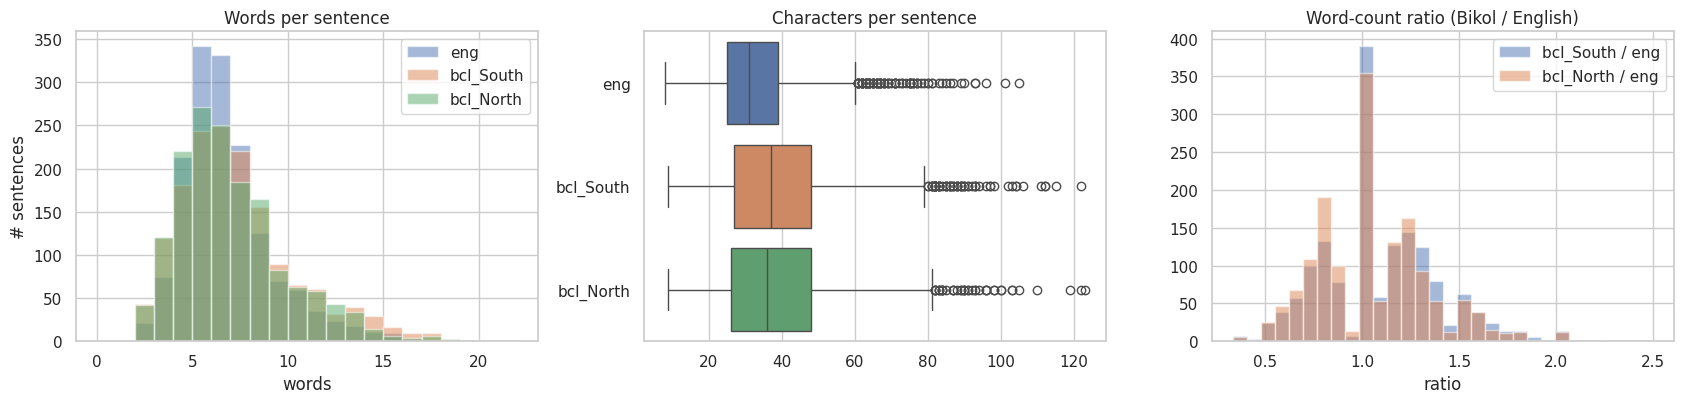

Length by split (mean/std words):


w_eng       w_bcl_South       w_bcl_North      
       mean   std        mean   std        mean   std
split                                                
test   6.51  2.61        7.00  3.45        6.77  3.34
train  6.26  2.38        6.76  3.05        6.47  2.80
val    6.51  2.38        7.18  3.06        6.83  2.70

In [13]:
for l in LANGS:
    df[f"w_{l}"] = df[l].map(lambda s: len(tok(s)))
    df[f"c_{l}"] = df[l].str.len()

pct = [.05, .25, .5, .75, .95]
wstats = pd.DataFrame({l: df[f"w_{l}"].describe(percentiles=pct) for l in LANGS}).round(2)
cstats = pd.DataFrame({l: df[f"c_{l}"].describe(percentiles=pct) for l in LANGS}).round(2)
print("Words per sentence"); display(wstats)
print("Characters per sentence"); display(cstats)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
bins = np.arange(0, max(df[[f"w_{l}" for l in LANGS]].max()) + 2)
for l in LANGS:
    ax[0].hist(df[f"w_{l}"], bins=bins, alpha=.5, label=l)
ax[0].set(title="Words per sentence", xlabel="words", ylabel="# sentences"); ax[0].legend()
sns.boxplot(data=df[[f"c_{l}" for l in LANGS]].rename(columns=lambda c: c[2:]), ax=ax[1], orient="h")
ax[1].set(title="Characters per sentence")
for l in BIKOL:
    ax[2].hist(df[f"w_{l}"] / df["w_eng"], bins=30, alpha=.5, label=f"{l} / eng")
ax[2].set(title="Word-count ratio (Bikol / English)", xlabel="ratio"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/sentence_lengths.png", dpi=150); plt.show()

# is each split representative?
by_split = df.groupby("split")[[f"w_{l}" for l in LANGS]].agg(["mean", "std"]).round(2)
print("Length by split (mean/std words):"); display(by_split)
wstats.to_csv(f"{OUT_DIR}/length_stats_words.csv"); cstats.to_csv(f"{OUT_DIR}/length_stats_chars.csv")

### 4.2 Token-to-Type Ratio (TTR)
Raw TTR falls as corpora grow, so three variants are reported: **TTR** = types/tokens, **Root TTR** = types/√tokens (Guiraud), and **MATTR** (moving-average TTR, window 500) which is comparable across sizes. A high **hapax ratio** (types seen once) signals sparsity — important for low-resource MT.

,sentences,tokens,types,TTR,root_TTR,MATTR_500,hapax_types,hapax_ratio_%,avg_tokens_per_sent,avg_word_len
eng,1569.0,9942.0,2343.0,0.236,23.498,0.547,1294.0,55.228,6.337,4.306
bcl_South,1569.0,10766.0,2608.0,0.242,25.135,0.482,1671.0,64.072,6.862,4.778
bcl_North,1569.0,10307.0,2566.0,0.249,25.275,0.490,1669.0,65.043,6.569,4.904


Train split only:


,sentences,tokens,types,TTR,root_TTR,MATTR_500,hapax_ratio_%
eng,1098.0,6876.0,1883.0,0.274,22.708,0.560,58.364
bcl_South,1098.0,7426.0,2057.0,0.277,23.870,0.497,65.873
bcl_North,1098.0,7104.0,2011.0,0.283,23.859,0.503,66.932


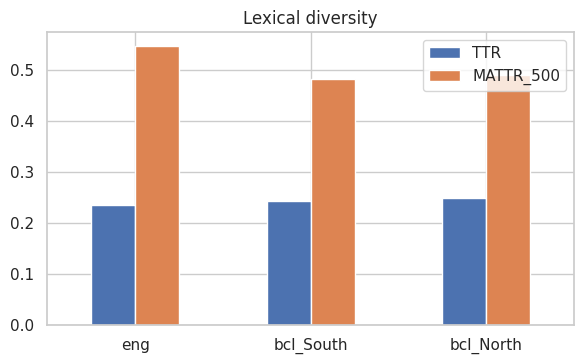

In [14]:
def mattr(tokens, window=500):
    if len(tokens) < window: return len(set(tokens)) / len(tokens)
    c = collections.Counter(tokens[:window]); vals = [len(c) / window]
    for i in range(window, len(tokens)):
        out, inn = tokens[i - window], tokens[i]
        c[out] -= 1
        if c[out] == 0: del c[out]
        c[inn] += 1; vals.append(len(c) / window)
    return float(np.mean(vals))

def vocab_stats(series):
    toks = [t for s in series for t in tok(s)]
    cnt = collections.Counter(toks)
    T, V = len(toks), len(cnt)
    return {"sentences": len(series), "tokens": T, "types": V, "TTR": V / T, "root_TTR": V / np.sqrt(T),
            "MATTR_500": mattr(toks), "hapax_types": sum(1 for c in cnt.values() if c == 1),
            "hapax_ratio_%": 100 * sum(1 for c in cnt.values() if c == 1) / V,
            "avg_tokens_per_sent": T / len(series), "avg_word_len": float(np.mean([len(t) for t in toks]))}

ttr = pd.DataFrame({l: vocab_stats(df[l]) for l in LANGS}).T.round(3)
display(ttr); ttr.to_csv(f"{OUT_DIR}/ttr_stats.csv")

# TTR on the training split only (what the model will actually learn from)
ttr_train = pd.DataFrame({l: vocab_stats(splits["train"][l]) for l in LANGS}).T.round(3)
print("Train split only:"); display(ttr_train[["sentences", "tokens", "types", "TTR", "root_TTR", "MATTR_500", "hapax_ratio_%"]])

ax = ttr[["TTR", "MATTR_500"]].plot.bar(figsize=(6, 3.8), rot=0, title="Lexical diversity")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/ttr.png", dpi=150); plt.show()

### 4.3 Vocabulary overlap between the three columns (Northern ↔ Southern ↔ English)
* **Jaccard** = |A∩B| / |A∪B| (type level)
* **Token coverage A→B** = % of A's running tokens whose type also occurs in B's vocabulary (how much of A a B-vocabulary could "read")

Type-level Jaccard


,eng,bcl_South,bcl_North
eng,1.000,0.033,0.038
bcl_South,0.033,1.000,0.281
bcl_North,0.038,0.281,1.000


Token coverage % (row language covered by column language's vocabulary)


,eng,bcl_South,bcl_North
eng,100.0,8.9,7.8
bcl_South,8.7,100.0,69.9
bcl_North,4.0,70.1,100.0


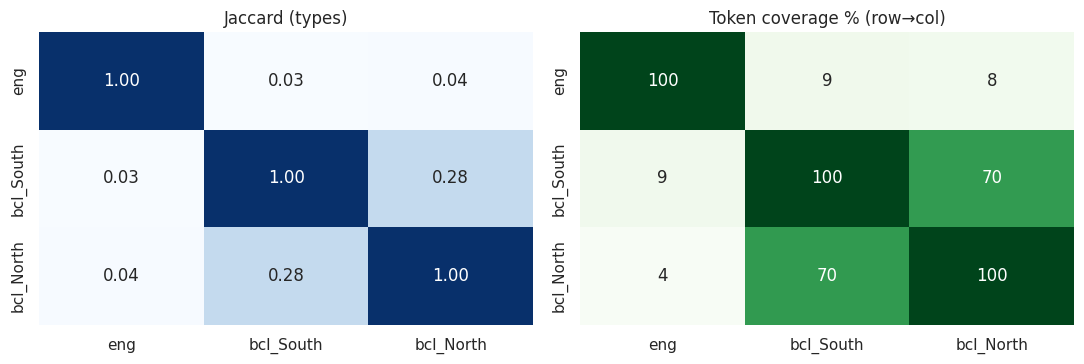

Sentences identical in Virac & Pandan: 43 (2.7%)
Words most characteristic of each dialect (appear in one vocabulary but never in the other):


,Pandan-only (North),freq_N,Virac-only (South),freq_S
0,yu,462,kan,140
1,mai,97,dai,107
2,atong,29,iyo,94
3,ninto,28,sya,47
4,iso,26,ngunyan,39
5,ardaw,23,so,36
6,baray,23,sinda,35
7,sadong,22,igwa,32
8,yun,19,ini,31
9,kiyang,18,halong,30


In [15]:
cnts = {l: collections.Counter(t for s in df[l] for t in tok(s)) for l in LANGS}
def jacc(a, b): A, B = set(a), set(b); return len(A & B) / len(A | B)
def cover(a, b): return 100 * sum(c for w, c in a.items() if w in b) / sum(a.values())

J = pd.DataFrame([[jacc(cnts[a], cnts[b]) for b in LANGS] for a in LANGS], index=LANGS, columns=LANGS).round(3)
CV = pd.DataFrame([[cover(cnts[a], cnts[b]) for b in LANGS] for a in LANGS], index=LANGS, columns=LANGS).round(1)
print("Type-level Jaccard"); display(J)
print("Token coverage % (row language covered by column language's vocabulary)"); display(CV)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(J, annot=True, fmt=".2f", cmap="Blues", ax=ax[0], cbar=False); ax[0].set_title("Jaccard (types)")
sns.heatmap(CV, annot=True, fmt=".0f", cmap="Greens", ax=ax[1], cbar=False); ax[1].set_title("Token coverage % (row→col)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/cross_dialect_overlap.png", dpi=150); plt.show()

same = int((df.k_bcl_South == df.k_bcl_North).sum())
print(f"Sentences identical in Virac & Pandan: {same} ({100*same/len(df):.1f}%)")
print("Words most characteristic of each dialect (appear in one vocabulary but never in the other):")
only_N = pd.Series({w: c for w, c in cnts["bcl_North"].items() if w not in cnts["bcl_South"]}).sort_values(ascending=False)
only_S = pd.Series({w: c for w, c in cnts["bcl_South"].items() if w not in cnts["bcl_North"]}).sort_values(ascending=False)
display(pd.DataFrame({"Pandan-only (North)": only_N.head(15).index, "freq_N": only_N.head(15).values,
                      "Virac-only (South)": only_S.head(15).index, "freq_S": only_S.head(15).values}))
J.to_csv(f"{OUT_DIR}/overlap_jaccard.csv"); CV.to_csv(f"{OUT_DIR}/overlap_token_coverage.csv")

### 4.4 Train → Validation/Test out-of-vocabulary (OOV) rate
Expected for a 1.5k-sentence corpus to be high; this is the baseline that Phase 2's subword tokenization / pre-trained model must overcome.

In [16]:
rows = []
for l in LANGS:
    tr = {t for s in splits["train"][l] for t in tok(s)}
    for s in ("val", "test"):
        toks = [t for x in splits[s][l] for t in tok(x)]
        oov = [t for t in toks if t not in tr]
        rows.append({"lang": l, "split": s, "tokens": len(toks), "OOV_token_%": 100 * len(oov) / len(toks),
                     "types": len(set(toks)), "OOV_type_%": 100 * len(set(oov)) / len(set(toks))})
oov_df = pd.DataFrame(rows).round(2); display(oov_df); oov_df.to_csv(f"{OUT_DIR}/oov_vs_train.csv", index=False)

,lang,split,tokens,OOV_token_%,types,OOV_type_%
0,eng,val,1537,17.83,734,35.29
1,eng,test,1529,15.57,697,32.42
2,bcl_South,val,1695,18.88,722,41.83
3,bcl_South,test,1645,16.90,689,39.04
4,bcl_North,val,1612,20.16,707,43.85
5,bcl_North,test,1591,17.10,673,39.23


### 4.5 Vocabulary overlap vs Central Bikol and Tagalog reference corpora
Reference vocabularies are built from **Wikipedia** (`wikimedia/wikipedia`, configs `20231101.bcl` = Central Bikol and `20231101.tl` = Tagalog). **English is included as a control** — it should overlap the least; if it doesn't, the reference is noisy.

Metrics per (language × reference × min-frequency filter): **type overlap %** (share of our vocabulary found in the reference), **token coverage %**, and **Jaccard**. The `min_freq ≥ 3` rows filter out one-off wiki noise (names, typos).

*If the download fails (no internet / dataset moved), put your own plain-text files in `REF_TEXT_FILES` below.*

In [17]:
REF_SOURCES = {
    "Central Bikol (bcl wiki)": {"config": "20231101.bcl", "max_articles": None},
    "Tagalog (tl wiki)":        {"config": "20231101.tl",  "max_articles": 40000},
}
REF_TEXT_FILES = {}   # fallback, e.g. {"Tagalog (own text)": "/content/tagalog.txt"}

def wiki_vocab(config, max_articles):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", config, split="train", streaming=True)
    cnt, n_art = collections.Counter(), 0
    for art in ds:
        cnt.update(tok(art["text"])); n_art += 1
        if max_articles and n_art >= max_articles: break
    return cnt, n_art

REF = {}
for name, cfg in REF_SOURCES.items():
    try:
        REF[name], n_art = wiki_vocab(**cfg)
        print(f"✅ {name}: {n_art:,} articles, {sum(REF[name].values()):,} tokens, {len(REF[name]):,} types")
    except Exception as e:
        print(f"⚠️ Could not load {name}: {type(e).__name__}: {str(e)[:120]}")
for name, path in REF_TEXT_FILES.items():
    with open(path, encoding="utf-8") as f: REF[name] = collections.Counter(tok(f.read()))
    print(f"✅ {name}: {len(REF[name]):,} types")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

✅ Central Bikol (bcl wiki): 15,743 articles, 2,815,197 tokens, 188,993 types
✅ Tagalog (tl wiki): 40,000 articles, 10,390,268 tokens, 383,597 types


,our_language,reference,ref_min_freq,our_types,ref_types,shared_types,type_overlap_%,token_coverage_%,jaccard
0,bcl_North,Central Bikol (bcl wiki),1,2566,188993,1403,54.677,80.208,0.007
1,bcl_North,Central Bikol (bcl wiki),3,2566,53096,1185,46.181,75.706,0.022
2,bcl_North,Tagalog (tl wiki),1,2566,383597,1269,49.454,75.580,0.003
3,bcl_North,Tagalog (tl wiki),3,2566,116680,1130,44.037,71.679,0.010
4,bcl_South,Central Bikol (bcl wiki),1,2608,188993,1683,64.532,88.250,0.009
5,bcl_South,Central Bikol (bcl wiki),3,2608,53096,1446,55.445,84.823,0.027
6,bcl_South,Tagalog (tl wiki),1,2608,383597,1402,53.758,78.739,0.004
7,bcl_South,Tagalog (tl wiki),3,2608,116680,1241,47.584,74.020,0.011
8,eng (control),Central Bikol (bcl wiki),1,2343,188993,1969,84.038,95.092,0.010
9,eng (control),Central Bikol (bcl wiki),3,2343,53096,1578,67.350,89.006,0.029


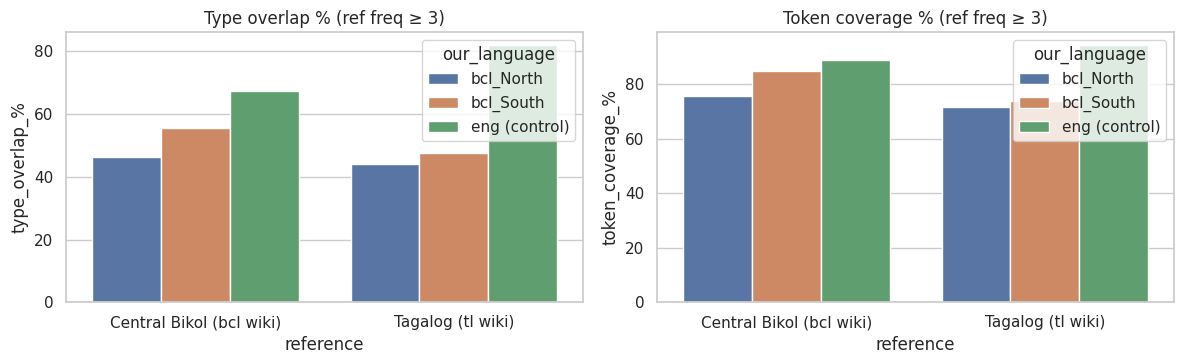


bcl_South: 863 types (33.1% of vocabulary) are absent from both references. Most frequent:
magkaon(14), sainyang(11), ilalom(10), halani(9), kamut(8), painano(8), madari(8), lagayon(8), purtahan(7), halalom(7), padpadon(7), haluon(6), madulom(6), maripot(6), saaga(5), magtalam(5), magkahang(5), mariput(5), saarin(5), gatao(5), nasabutan(5), saladay(5), masilam(4), kuhaon(4), gahalat(4)

bcl_North: 1,096 types (42.7% of vocabulary) are absent from both references. Most frequent:
turtor(36), ninto(28), baray(23), ardaw(23), sadong(22), kiyang(18), tinaman(17), siin(16), madyag(15), kadakor(15), tayon(15), loog(13), ibutang(12), sakiyang(12), magkaon(11), dwaging(11), nintong(11), saako(11), ilarom(10), siki(10), magbutang(10), tinahan(9), saaga(9), hawong(9), purtahan(8)


In [18]:
def overlap_row(target, ref, min_freq):
    rv = {w for w, c in ref.items() if c >= min_freq}; tv = set(target)
    inter = tv & rv
    return {"our_types": len(tv), "ref_types": len(rv), "shared_types": len(inter),
            "type_overlap_%": 100 * len(inter) / len(tv),
            "token_coverage_%": 100 * sum(target[w] for w in inter) / sum(target.values()),
            "jaccard": len(inter) / len(tv | rv)}

if REF:
    rows = []
    for l in ["bcl_North", "bcl_South", "eng"]:
        for rname, rc in REF.items():
            for mf in (1, 3):
                rows.append({"our_language": l + (" (control)" if l == "eng" else ""), "reference": rname, "ref_min_freq": mf,
                             **overlap_row(cnts[l], rc, mf)})
    ref_df = pd.DataFrame(rows).round(3)
    display(ref_df); ref_df.to_csv(f"{OUT_DIR}/overlap_vs_reference.csv", index=False)

    plot = ref_df[ref_df.ref_min_freq == 3]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    sns.barplot(data=plot, x="reference", y="type_overlap_%", hue="our_language", ax=ax[0]); ax[0].set_title("Type overlap % (ref freq ≥ 3)")
    sns.barplot(data=plot, x="reference", y="token_coverage_%", hue="our_language", ax=ax[1]); ax[1].set_title("Token coverage % (ref freq ≥ 3)")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/overlap_vs_reference.png", dpi=150); plt.show()

    # dialect-specific lexicon: frequent words in our data that neither reference knows -> prime OOV/error-analysis candidates
    known = set()
    for rc in REF.values(): known |= {w for w, c in rc.items() if c >= 2}
    for l in BIKOL:
        miss = pd.Series({w: c for w, c in cnts[l].items() if w not in known}).sort_values(ascending=False)
        miss.rename("freq").rename_axis("token").reset_index().to_csv(f"{OUT_DIR}/{l}_words_absent_from_references.csv", index=False)
        print(f"\n{l}: {len(miss):,} types ({100*len(miss)/len(cnts[l]):.1f}% of vocabulary) are absent from both references. Most frequent:")
        print(", ".join(f"{w}({c})" for w, c in miss.head(25).items()))
else:
    print("No reference vocabularies loaded — skipping 4.5 (see REF_TEXT_FILES fallback above).")

## 5. Summary report & export

In [19]:
summary = {
    "rows_raw": cleaning_log["rows_raw"], "rows_final": len(df),
    "cleaning_steps": cleaning_log,
    "split_sizes": {s: len(d) for s, d in splits.items()},
    "n_leakage_groups": int(df.group.nunique()),
    "near_dup_threshold": NEAR_DUP_THRESH, "seed": SEED,
    "ttr": ttr[["tokens", "types", "TTR", "root_TTR", "MATTR_500"]].to_dict("index"),
    "settings": {"strip_bikol_diacritics": STRIP_BIKOL_DIACRITICS, "variant_map": VARIANT_MAP},
}
with open(f"{OUT_DIR}/phase1_summary.json", "w", encoding="utf-8") as f: json.dump(summary, f, indent=2, ensure_ascii=False)
print(json.dumps({k: summary[k] for k in ["rows_raw", "rows_final", "split_sizes", "n_leakage_groups"]}, indent=2))

ZIP = "phase1_outputs.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(OUT_DIR):
        for f in fs: z.write(os.path.join(root, f))
print("Created", ZIP, "->", sorted(os.listdir(OUT_DIR)))

# optional: keep a copy on Google Drive
# from google.colab import drive; drive.mount('/content/drive'); !cp -r phase1_outputs /content/drive/MyDrive/
if IN_COLAB: files.download(ZIP)

{
  "rows_raw": 1597,
  "rows_final": 1569,
  "split_sizes": {
    "train": 1098,
    "val": 236,
    "test": 235
  },
  "n_leakage_groups": 1550
}
Created phase1_outputs.zip -> ['bcl_North_words_absent_from_references.csv', 'bcl_South_words_absent_from_references.csv', 'corpus_clean_all.csv', 'directional', 'figures', 'length_stats_chars.csv', 'length_stats_words.csv', 'oov_vs_train.csv', 'overlap_jaccard.csv', 'overlap_token_coverage.csv', 'overlap_vs_reference.csv', 'phase1_summary.json', 'possible_misalignments_review.csv', 'spelling_variant_candidates.csv', 'test.csv', 'test.json', 'train.csv', 'train.json', 'ttr_stats.csv', 'val.csv', 'val.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### What to put in your README / report for Phase 1
* **Sourcing & cleaning**: `phase1_summary.json → cleaning_steps` lists every step and how many cells it changed.
* **Spelling standardization**: describe the `VARIANT_MAP` and who reviewed it; keep `spelling_variant_candidates.csv` as evidence.
* **Split protocol**: seed, group-aware method, near-duplicate threshold, and the ✅ leakage assertions.
* **Vocabulary analysis**: figures in `figures/`, tables in the CSVs.
* **Phase 2 hand-off**: `directional/*.jsonl` (six directions × train/val/test). Note that NLLB-200 has no Bikol language code, so you'll need to pick a proxy code (e.g. `tgl_Latn`) or add new language tokens when you set up fine-tuning.

---
---
# Phase 2 — Model Fine-Tuning & PEFT/LoRA Optimization (Weeks 3–5)
**Tasks 2.1 – 2.4.** This part continues directly from Phase 1 (it reads `phase1_outputs/directional/*.jsonl`).

| Task | What this part does |
|---|---|
| **2.1** Base model selection | Loads `facebook/nllb-200-distilled-600M`, gives **each language its own tag**, measures a **zero-shot baseline** on the validation set |
| **2.2** LoRA setup | Freezes the base model; trains low-rank matrices on all attention **and feed-forward** linears (`q/k/v/out_proj`, `fc1`, `fc2`; r=64, α=128, dropout 0.1, lr 3e-4) |
| **2.3** Training & checkpointing | ONE adapter trained on **all 6 directions: English↔North, English↔South and South↔North**; label smoothing; the best epoch is chosen by **validation BLEU** (not loss), with early stopping |
| **2.4** Export | Saves the adapter, reloads it dynamically, merges it, makes fp16 and int8 versions, and benchmarks **size / latency / quality** of each |

⚠️ **Use a GPU runtime** (Runtime → Change runtime type → T4 GPU).
⚠️ **The test set is never loaded in Phase 2.** Model selection uses the validation set only; the test set is reserved for Phase 4.

> **v4 changes (vs v3) — fighting over-fitting.** v3 reached mean validation BLEU 24.4 but memorised its ~1,100 training sentences (train-row chrF++ 82–95 vs validation 45–51; validation loss rose from epoch 4). The corpus itself cannot be enlarged by code, so v4 regularises:
> LoRA r=32 / dropout 0.2, weight decay 0.05, label smoothing 0.15, **random source-token dropout (10 %)**, a lower learning rate (2e-4), the best epoch chosen on **all** validation sentences, and 95 % bootstrap confidence intervals so BLEU differences can be judged. It also fixes a resume bug (a finished run was "resumed" and its best-epoch label was wrong) and the log spam.
> These settings are expected to reduce the train/validation gap; whether they raise BLEU has to be measured by running it.
>
> **v3 changes (vs v2):** South↔North added to training; separate language tags (`tgl_Latn`, `war_Latn`, `eng_Latn`); ~3× more training examples; best epoch chosen by validation BLEU instead of loss.
>
> Reference validation BLEU — v2: N→Eng 25.4, Eng→N 20.3, S→Eng 30.1, Eng→S 16.8. v3: 27.2 / 21.3 / 29.1 / 19.0, S→N 25.6, N→S 24.2.


## 2.0 Setup

In [20]:
!pip -q uninstall -y torchao
!pip -q install -U peft accelerate sacrebleu sentencepiece

In [21]:
import copy, time, shutil, gc, math, inspect, dataclasses, zipfile, json, os, sys, subprocess, importlib, collections
import importlib.metadata as importlib_md

def ensure_torchao_ok(min_version="0.16.0"):
    """Colab ships an old torchao that makes peft raise ImportError. LoRA does not need torchao -> remove it if too old."""
    from packaging import version
    try: v = importlib_md.version("torchao")
    except importlib_md.PackageNotFoundError: return
    if version.parse(v) < version.parse(min_version):
        print(f"torchao {v} is incompatible with this peft version -> uninstalling it (not needed for LoRA)")
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"], check=False, capture_output=True)
        importlib.invalidate_caches()
        for k in [k for k in sys.modules if k == "torchao" or k.startswith("torchao.")]: del sys.modules[k]
        try:
            import peft.import_utils as _iu; _iu.is_torchao_available.cache_clear()
        except Exception: pass
ensure_torchao_ok()

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, transformers, peft, sacrebleu
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, TrainingArguments, Trainer,
                          DataCollatorForSeq2Seq, EarlyStoppingCallback, set_seed)
from peft import LoraConfig, TaskType, get_peft_model, PeftModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__}")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NO GPU — training will be extremely slow!")

torch 2.14.1+cu130 | transformers 5.22.1 | peft 0.21.3
Device: cuda | Tesla T4


## 2.1 Base Model Selection

| Candidate | Size | Why / why not |
|---|---|---|
| **`facebook/nllb-200-distilled-600M`** ✅ | ≈ 600 M | Pre-trained for translation on 200 languages **including Tagalog, Cebuano, Waray, Ilocano and Pangasinan** — the closest relatives of Bikol it has seen. Fits a free T4 with LoRA. |
| `facebook/mbart-large-50` | ≈ 610 M | Multilingual translation model, but fewer languages and no other Philippine languages besides Tagalog. |
| `google/mt5-base` | ≈ 580 M | Only denoising-pre-trained (no translation training) → needs far more data to translate well. |

### The language-code problem (important)
NLLB-200 has **no language code for Bikol**. Adding brand-new language tokens would give randomly-initialised embeddings that LoRA cannot learn well from ~1 k pairs. So this notebook re-uses **existing NLLB tags as proxies**:

| Language | Proxy tag | Note |
|---|---|---|
| English | `eng_Latn` | native |
| Northern Bikol (Pandan) | `tgl_Latn` | Tagalog — closest high-resource relative, many loanwords |
| Southern Bikol (Virac) | `war_Latn` | Waray — another Central Philippine language; any unused related tag works, the adapter re-learns what it means |

Each language needs a **different** tag: with one shared tag, a South→North request would have the same source and target tag and the model could not know which dialect to produce. With distinct tags **one adapter handles all six directions**, and the tag alone selects the output dialect.


In [22]:
# ========================== PHASE 2 CONFIG (v4) ==========================
import transformers; transformers.logging.set_verbosity_error()   # hides the "max_new_tokens / max_length" warning that was printed thousands of times
MODEL_NAME = "facebook/nllb-200-distilled-600M"   # bigger option for higher BLEU: an NLLB-1.3B model (T4: BATCH_SIZE=8, GRAD_ACCUM=2; slower, may miss the <300 ms target)

# --- proxy language tags (NLLB-200 has no Bikol): every language gets its OWN existing NLLB tag ---
CODE = {"eng": "eng_Latn", "bcl_North": "tgl_Latn", "bcl_South": "war_Latn"}
assert len(set(CODE.values())) == len(CODE), "every language needs its own tag"

ALL_DIRECTIONS = [("bcl_North", "eng"), ("eng", "bcl_North"),
                  ("bcl_South", "eng"), ("eng", "bcl_South"),
                  ("bcl_South", "bcl_North"), ("bcl_North", "bcl_South")]
RUN_SPECS = {
    "multi":             ALL_DIRECTIONS,       # RECOMMENDED: one adapter, 6 directions, regularised (v4)
    "multi_v3_baseline": ALL_DIRECTIONS,       # the v3 settings (over-fitted), only if you want to re-measure them
    "ablation_eng_only": ALL_DIRECTIONS[:4],   # regularised, but WITHOUT South<->North
}

# --- regularisation presets ---
# v3 over-fitted: train-row chrF++ 82-95 vs validation 45-51, validation loss rising from epoch 4, only ~1,100 unique sentences.
# v4 = smaller/more-dropped adapter + stronger weight decay + label smoothing + random SOURCE-token dropout (noise on the input only).
REG = dict(LORA_R=32, LORA_ALPHA=64,  LORA_DROPOUT=0.2, LR=2e-4, WEIGHT_DECAY=0.05, LABEL_SMOOTHING=0.15, SRC_TOKEN_DROPOUT=0.10)
V3  = dict(LORA_R=64, LORA_ALPHA=128, LORA_DROPOUT=0.1, LR=3e-4, WEIGHT_DECAY=0.01, LABEL_SMOOTHING=0.10, SRC_TOKEN_DROPOUT=0.0)
RUN_HP = {"multi": REG, "multi_v3_baseline": V3, "ablation_eng_only": REG}

RUN_NAME   = "multi"
DIRECTIONS = RUN_SPECS[RUN_NAME]
PAIR       = DIRECTIONS[0]                     # "primary" direction: latency benchmark and demo sentence
globals().update(RUN_HP[RUN_NAME])             # LORA_R, LORA_ALPHA, LORA_DROPOUT, LR, WEIGHT_DECAY, LABEL_SMOOTHING, SRC_TOKEN_DROPOUT
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"]

# --- training ---
EPOCHS                = 30                # the best epoch is chosen by validation BLEU; early stopping ends it sooner
BATCH_SIZE, GRAD_ACCUM = 16, 1
WARMUP_FRAC           = 0.06
EARLY_STOP_PATIENCE   = 5                 # epochs without a validation-BLEU gain
EVAL_N_PER_DIR        = 10_000            # decode ALL validation sentences of every direction each epoch (less noisy than a subset)
MAX_LEN               = 64
RESUME                = False             # True -> resume an UNFINISHED run from its last checkpoint after a Colab disconnect

USE_DRIVE    = False
PUSH_TO_HUB  = False
HF_REPO      = "your-username/nllb-bikol-lora"
# =====================================================================

P2_ROOT = "phase2_outputs"
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    P2_ROOT = "/content/drive/MyDrive/bikol_nmt/phase2_outputs"
P2_DIR = f"{P2_ROOT}/{RUN_NAME}"
os.makedirs(f"{P2_DIR}/figures", exist_ok=True)
SEED = globals().get("SEED", 42)
set_seed(SEED)
print("Run:", RUN_NAME, "| outputs ->", P2_DIR)
print("Directions:", DIRECTIONS)
print("Hyper-parameters:", {k: globals()[k] for k in RUN_HP[RUN_NAME]})


Run: multi | outputs -> phase2_outputs/multi
Directions: [('bcl_North', 'eng'), ('eng', 'bcl_North'), ('bcl_South', 'eng'), ('eng', 'bcl_South'), ('bcl_South', 'bcl_North'), ('bcl_North', 'bcl_South')]
Hyper-parameters: {'LORA_R': 32, 'LORA_ALPHA': 64, 'LORA_DROPOUT': 0.2, 'LR': 0.0002, 'WEIGHT_DECAY': 0.05, 'LABEL_SMOOTHING': 0.15, 'SRC_TOKEN_DROPOUT': 0.1}


In [23]:
# ---- make sure the Phase 1 outputs exist (works also when Phase 2 is run in a fresh session) ----
P1_DIR = OUT_DIR if "OUT_DIR" in globals() else "phase1_outputs"
if not os.path.isdir(f"{P1_DIR}/directional"):
    if not os.path.exists("phase1_outputs.zip"):
        try:
            from google.colab import files as _f
            print("Upload phase1_outputs.zip (created at the end of Phase 1) ...")
            _f.upload()
        except ImportError:
            raise FileNotFoundError("phase1_outputs/ not found — run Phase 1 first")
    zipfile.ZipFile("phase1_outputs.zip").extractall(".")
    P1_DIR = "phase1_outputs"

def read_jsonl(path):
    with open(path, encoding="utf-8") as f: return [json.loads(l) for l in f]

train_rows  = [r for s, t in DIRECTIONS for r in read_jsonl(f"{P1_DIR}/directional/train.{s}-{t}.jsonl")]
VAL_BY_DIR  = {d: read_jsonl(f"{P1_DIR}/directional/val.{d[0]}-{d[1]}.jsonl") for d in DIRECTIONS}
val_rows    = [r for rows in VAL_BY_DIR.values() for r in rows]
print(f"train examples: {len(train_rows)} | val examples: {len(val_rows)}   (test set intentionally NOT loaded)")
for r in train_rows[:3]: print(r)

train examples: 6582 | val examples: 1416   (test set intentionally NOT loaded)
{'src_lang': 'bcl_North', 'tgt_lang': 'eng', 'src': 'Layalaya ko sa biyaheng ibisag yan.', 'tgt': 'I got extremely dizzy from the trip.'}
{'src_lang': 'bcl_North', 'tgt_lang': 'eng', 'src': 'Mai mo na siya paghamason.', 'tgt': "Don't chase after him/her anymore."}
{'src_lang': 'bcl_North', 'tgt_lang': 'eng', 'src': 'Pagtungog daw sa langag!', 'tgt': 'Stay in the house!'}


In [24]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, src_lang=CODE[PAIR[0]], tgt_lang=CODE[PAIR[1]])

def encode_pairs(rows):
    feats = []
    for r in rows:
        tokenizer.src_lang, tokenizer.tgt_lang = CODE[r["src_lang"]], CODE[r["tgt_lang"]]
        enc = tokenizer(r["src"], text_target=r["tgt"], max_length=MAX_LEN, truncation=True)
        feats.append({"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "labels": enc["labels"]})
    return feats

train_data, val_data = encode_pairs(train_rows), encode_pairs(val_rows)

# sanity: sequence lengths vs MAX_LEN, and what the special tokens look like
L_src = np.array([len(x["input_ids"]) for x in train_data]); L_tgt = np.array([len(x["labels"]) for x in train_data])
print(f"source tokens: mean {L_src.mean():.1f}, p95 {np.percentile(L_src,95):.0f}, max {L_src.max()} | target tokens: mean {L_tgt.mean():.1f}, p95 {np.percentile(L_tgt,95):.0f}, max {L_tgt.max()}")
print(f"examples hitting MAX_LEN={MAX_LEN} (truncated): {int(((L_src>=MAX_LEN)|(L_tgt>=MAX_LEN)).sum())}")
print("\nExample encoding:")
print(" input :", tokenizer.convert_ids_to_tokens(train_data[0]["input_ids"]))
print(" labels:", tokenizer.convert_ids_to_tokens(train_data[0]["labels"]))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/3.55k [00:00<?, ?B/s]

source tokens: mean 12.4, p95 21, max 35 | target tokens: mean 12.4, p95 21, max 35
examples hitting MAX_LEN=64 (truncated): 0

Example encoding:
 input : ['tgl_Latn', '▁L', 'aya', 'laya', '▁ko', '▁sa', '▁bi', 'yah', 'eng', '▁ibis', 'ag', '▁yan', '.', '</s>']
 labels: ['eng_Latn', '▁I', '▁got', '▁extremely', '▁di', 'zzy', '▁from', '▁the', '▁trip', '.', '</s>']


### 2.1b Helpers: translation, scoring, zero-shot baseline
Metrics are **BLEU, chrF++ and TER** (SacreBLEU) on the **validation** set. Higher is better for BLEU/chrF++, *lower* for TER.

In [25]:
def load_base():
    return AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE)

@torch.no_grad()
def translate(model, texts, src_lang, tgt_lang, num_beams=4, bs=32, max_new_tokens=96, device=None, amp_on=True):
    device = device or DEVICE
    model.eval()
    tokenizer.src_lang = CODE[src_lang]
    forced = tokenizer.convert_tokens_to_ids(CODE[tgt_lang])
    order = np.argsort([-len(t) for t in texts]); out = [None] * len(texts)
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        enc = tokenizer([texts[j] for j in idx], return_tensors="pt", padding=True, truncation=True, max_length=MAX_LEN).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
            gen = model.generate(**enc, forced_bos_token_id=forced, num_beams=num_beams, max_new_tokens=max_new_tokens)
        for j, d in zip(idx, tokenizer.batch_decode(gen, skip_special_tokens=True)): out[j] = d
    return out

def score(hyps, refs):
    return {"BLEU": sacrebleu.corpus_bleu(hyps, [refs]).score,
            "chrF++": sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score,
            "TER": sacrebleu.corpus_ter(hyps, [refs]).score}

def eval_model(model, label, num_beams=4, limit=None, **kw):
    res, preds = [], {}
    for (s, t), rows in VAL_BY_DIR.items():
        srcs = [r["src"] for r in rows][:limit]; refs = [r["tgt"] for r in rows][:limit]
        hyps = translate(model, srcs, s, t, num_beams=num_beams, **kw)
        res.append({"model": label, "direction": f"{s} → {t}", "n": len(srcs), **score(hyps, refs)})
        preds[(s, t)] = (srcs, refs, hyps)
    return pd.DataFrame(res), preds

In [26]:
# ---- Zero-shot baseline: the un-tuned base model, Bikol tagged as Tagalog ----
base = load_base()
zs_df, zs_preds = eval_model(base, "Zero-shot NLLB-600M")
display(zs_df.round(2))
del base; gc.collect(); torch.cuda.empty_cache()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.46GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

,model,direction,n,BLEU,chrF++,TER
0,Zero-shot NLLB-600M,bcl_North → eng,236,12.08,32.81,86.80
1,Zero-shot NLLB-600M,eng → bcl_North,236,3.97,27.30,100.81
2,Zero-shot NLLB-600M,bcl_South → eng,236,15.91,36.44,80.92
3,Zero-shot NLLB-600M,eng → bcl_South,236,1.68,25.35,98.47
4,Zero-shot NLLB-600M,bcl_South → bcl_North,236,4.06,27.22,98.51
5,Zero-shot NLLB-600M,bcl_North → bcl_South,236,2.66,24.44,102.30


## 2.2 Parameter-Efficient Fine-Tuning — LoRA setup
LoRA freezes every base weight and learns a low-rank update **ΔW = (α/r)·B·A** inside every attention projection (`q/k/v/out_proj`) **and** the feed-forward layers (`fc1`, `fc2`). v4 uses **r = 32, α = 64, dropout 0.2** (≈ 17 M trainable parameters, adapter ≈ 70 MB in fp32): v3's r = 64 had enough capacity to memorise the training set, so the adapter is made smaller and noisier.


In [27]:
def make_lora_model(r, alpha, dropout=LORA_DROPOUT, targets=None):
    base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)      # fp32 base; fp16 only via AMP -> stable gradients
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout, target_modules=targets or TARGET_MODULES,
                     bias="none", task_type=TaskType.SEQ_2_SEQ_LM)
    return get_peft_model(base, cfg)

ensure_torchao_ok()
_demo = make_lora_model(LORA_R, LORA_ALPHA)
_demo.print_trainable_parameters()
lora_modules = [n for n, _ in _demo.named_modules() if n.endswith("lora_A")]
print(f"{len(lora_modules)} LoRA-wrapped linear layers, e.g.:\n  " + "\n  ".join(lora_modules[:3]))
assert all(("lora_" in n) for n, p in _demo.named_parameters() if p.requires_grad), "a non-LoRA weight is trainable!"
print("✅ only LoRA weights are trainable; base model is frozen")
del _demo; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360
192 LoRA-wrapped linear layers, e.g.:
  base_model.model.model.encoder.layers.0.self_attn.k_proj.lora_A
  base_model.model.model.encoder.layers.0.self_attn.v_proj.lora_A
  base_model.model.model.encoder.layers.0.self_attn.q_proj.lora_A
✅ only LoRA weights are trainable; base model is frozen


## 2.3 Training & checkpointing
* **AdamW**, linear decay with warmup, lr 2e-4, weight decay 0.05, fp16 mixed precision, batch 16
* **Regularisation:** label smoothing 0.15 and random **source-token dropout** (10 % of source tokens → `<unk>`, training only)
* Trained on **all six directions at once** (English↔North, English↔South, South↔North)
* After every epoch **all** validation sentences of every direction are decoded and scored; the adapter with the **highest mean validation BLEU** is kept and training stops after 5 epochs without improvement
* A `train_done.json` marker stops the runner from "resuming" a run that already finished


In [28]:
from transformers import TrainerCallback
from peft import get_peft_model_state_dict, set_peft_model_state_dict

class BleuSelect(TrainerCallback):
    # After every epoch: greedy-decode a fixed validation subset of EVERY direction, compute mean BLEU / chrF++,
    # keep the best adapter weights, and stop when BLEU has not improved for `patience` epochs.
    # (Validation LOSS starts rising after ~6 epochs on this tiny corpus while BLEU can still improve, so loss is the wrong selector.)
    def __init__(self, patience, n_per_dir, best_dir, resume=False):
        rs = np.random.default_rng(SEED)
        self.subset = {}
        for d, rows in VAL_BY_DIR.items():
            idx = sorted(rs.choice(len(rows), size=min(n_per_dir, len(rows)), replace=False))
            self.subset[d] = [rows[i] for i in idx]
        self.patience, self.best_dir = patience, best_dir
        self.best, self.best_epoch, self.best_state, self.bad, self.history = -1.0, 0, None, 0, []
        sp = f"{best_dir}/best_score.json"
        if resume and os.path.exists(sp):
            j = json.load(open(sp)); self.best, self.best_epoch = j["bleu"], j["epoch"]
        hp = f"{best_dir}/history.json"                  # per-epoch BLEU of the epochs before the resume (otherwise they show as NaN)
        if resume and os.path.exists(hp): self.history = json.load(open(hp))

    def on_epoch_end(self, args, state, control, model=None, **kw):
        ep, bl, cf = int(round(state.epoch)), [], []
        for (s, t), rows in self.subset.items():
            hyps, refs = translate(model, [r["src"] for r in rows], s, t, num_beams=1, bs=64), [r["tgt"] for r in rows]
            bl.append(sacrebleu.corpus_bleu(hyps, [refs]).score)
            cf.append(sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score)
        b, c = float(np.mean(bl)), float(np.mean(cf))
        self.history.append({"epoch": ep, "val_BLEU": b, "val_chrF++": c})
        os.makedirs(self.best_dir, exist_ok=True); json.dump(self.history, open(f"{self.best_dir}/history.json", "w"))
        if b > self.best + 1e-6:
            self.best, self.best_epoch, self.bad = b, ep, 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(model).items()}
            os.makedirs(self.best_dir, exist_ok=True); model.save_pretrained(self.best_dir)
            json.dump({"bleu": b, "epoch": ep}, open(f"{self.best_dir}/best_score.json", "w"))
        else:
            self.bad += 1
        print(f"   [epoch {ep}] val BLEU {b:.2f} | chrF++ {c:.2f}  (mean over {len(bl)} directions, greedy)  | best {self.best:.2f} @ epoch {self.best_epoch}")
        if self.bad >= self.patience:
            print(f"   early stop: no validation-BLEU gain for {self.patience} epochs"); control.should_training_stop = True
        return control

class LSTrainer(Trainer):
    # Label smoothing done here instead of via TrainingArguments(label_smoothing_factor): that option makes the Trainer pop `labels`
    # before the forward pass, and NLLB then gets no decoder_input_ids ("cannot specify both decoder_input_ids and decoder_inputs_embeds").
    # Here `labels` still reach the model (it shifts them into decoder inputs); smoothing is applied only while training,
    # so the validation loss stays a plain cross-entropy.
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        if model.training and SRC_TOKEN_DROPOUT > 0:        # input noise: randomly replace source tokens by <unk> (never the language tag, </s> or padding)
            ids = inputs["input_ids"]
            drop = (torch.rand(ids.shape, device=ids.device) < SRC_TOKEN_DROPOUT) & (inputs["attention_mask"] == 1) & (ids != tokenizer.eos_token_id)
            drop[:, 0] = False
            inputs = {**inputs, "input_ids": ids.masked_fill(drop, tokenizer.unk_token_id)}
        outputs = model(**inputs)
        logits = outputs.logits
        loss = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), labels.reshape(-1), ignore_index=-100,
                                                 label_smoothing=LABEL_SMOOTHING if model.training else 0.0)
        return (loss, outputs) if return_outputs else loss

def train_lora(r, alpha, dropout=LORA_DROPOUT, lr=LR, epochs=EPOCHS, out_dir=None, patience=EARLY_STOP_PATIENCE,
               resume=False, verbose=True, targets=None):
    set_seed(SEED)
    if out_dir and os.path.exists(f"{out_dir}/train_done.json"): os.remove(f"{out_dir}/train_done.json")   # a new training run is starting
    model = make_lora_model(r, alpha, dropout, targets)
    if verbose: model.print_trainable_parameters()

    total_steps = math.ceil(len(train_data) / (BATCH_SIZE * GRAD_ACCUM)) * epochs
    kw = dict(output_dir=out_dir, num_train_epochs=epochs, per_device_train_batch_size=BATCH_SIZE,
              per_device_eval_batch_size=BATCH_SIZE * 2, gradient_accumulation_steps=GRAD_ACCUM,
              learning_rate=lr, lr_scheduler_type="linear", warmup_steps=int(WARMUP_FRAC * total_steps),
              optim="adamw_torch", weight_decay=WEIGHT_DECAY,
              fp16=(DEVICE == "cuda"), logging_strategy="epoch", save_strategy="epoch", save_total_limit=2,
              load_best_model_at_end=False,            # best epoch is chosen by validation BLEU in BleuSelect, not by loss
              report_to="none", seed=SEED, remove_unused_columns=False, label_names=["labels"])
    # argument was renamed evaluation_strategy -> eval_strategy in newer transformers
    fields = {f.name for f in dataclasses.fields(TrainingArguments)}
    kw["eval_strategy" if "eval_strategy" in fields else "evaluation_strategy"] = "epoch"
    args = TrainingArguments(**kw)

    tkw = ({"processing_class": tokenizer} if "processing_class" in inspect.signature(Trainer.__init__).parameters
           else {"tokenizer": tokenizer})
    cb = BleuSelect(patience, EVAL_N_PER_DIR, f"{out_dir}/best_by_bleu", resume=resume)
    trainer = LSTrainer(model=model, args=args, train_dataset=train_data, eval_dataset=val_data,
                      data_collator=DataCollatorForSeq2Seq(tokenizer, model=None, padding=True, pad_to_multiple_of=8, label_pad_token_id=-100),
                      callbacks=[cb], **tkw)
    trainer.train(resume_from_checkpoint=True if resume else None)

    # restore the best-BLEU epoch (not the last one)
    state = cb.best_state
    if state is None and os.path.exists(f"{cb.best_dir}/adapter_model.safetensors"):      # after a resumed run
        from safetensors.torch import load_file; state = load_file(f"{cb.best_dir}/adapter_model.safetensors")
    if state is not None:
        set_peft_model_state_dict(model, state)
        if verbose: print(f"✅ restored best-BLEU weights from epoch {cb.best_epoch} (mean val BLEU {cb.best:.2f})")

    log = trainer.state.log_history
    tr = {int(round(h["epoch"])): h["loss"] for h in log if "loss" in h and "eval_loss" not in h}
    ev = {int(round(h["epoch"])): h["eval_loss"] for h in log if "eval_loss" in h}
    bl = {h["epoch"]: h["val_BLEU"] for h in cb.history}; cf = {h["epoch"]: h["val_chrF++"] for h in cb.history}
    hist = (pd.DataFrame({"epoch": sorted(ev)}).assign(train_loss=lambda d: d.epoch.map(tr), val_loss=lambda d: d.epoch.map(ev),
                                                       val_BLEU=lambda d: d.epoch.map(bl)))
    hist["val_chrF++"] = hist.epoch.map(cf)
    if out_dir:                                          # marks the run as finished so the runner never "resumes" a completed run
        json.dump({"best_epoch": cb.best_epoch, "best_val_BLEU": cb.best}, open(f"{out_dir}/train_done.json", "w"))
    return model, trainer, hist

print("steps/epoch:", math.ceil(len(train_data) / (BATCH_SIZE * GRAD_ACCUM)), "| max total:", math.ceil(len(train_data) / (BATCH_SIZE * GRAD_ACCUM)) * EPOCHS)


steps/epoch: 412 | max total: 12360


In [29]:
t0 = time.time()
model, trainer, hist = train_lora(LORA_R, LORA_ALPHA, out_dir=f"{P2_DIR}/checkpoints", resume=RESUME)
print(f"\nTraining finished in {(time.time()-t0)/60:.1f} min")
hist.to_csv(f"{P2_DIR}/loss_history.csv", index=False)
display(hist.round(4))

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360
   [epoch 1] val BLEU 14.12 | chrF++ 36.90  (mean over 6 directions, greedy)  | best 14.12 @ epoch 1
{'loss': '5.235', 'grad_norm': '2.219', 'learning_rate': '0.0001109', 'epoch': '1'}
{'eval_loss': '2.542', 'eval_runtime': '6.743', 'eval_samples_per_second': '210', 'eval_steps_per_second': '6.674', 'epoch': '1'}
   [epoch 2] val BLEU 16.60 | chrF++ 39.75  (mean over 6 directions, greedy)  | best 16.60 @ epoch 2
{'loss': '4.493', 'grad_norm': '3.286', 'learning_rate': '0.0001986', 'epoch': '2'}
{'eval_loss': '2.321', 'eval_runtime': '6.825', 'eval_samples_per_second': '207.5', 'eval_steps_per_second': '6.593', 'epoch': '2'}
   [epoch 3] val BLEU 19.15 | chrF++ 41.92  (mean over 6 directions, greedy)  | best 19.15 @ epoch 3
{'loss': '4.239', 'grad_norm': '2.742', 'learning_rate': '0.0001915', 'epoch': '3'}
{'eval_loss': '2.165', 'eval_runtime': '6.591', 'eval_samples_per_second': '214.8', 'eval_steps_per_secon

,epoch,train_loss,val_loss,val_BLEU,val_chrF++
0,1,5.2354,2.5422,14.1157,36.9036
1,2,4.4926,2.3208,16.5963,39.7543
2,3,4.2394,2.1649,19.1464,41.9212
3,4,4.0562,2.0998,20.3134,42.9485
4,5,3.9136,2.0427,20.9284,44.0744
5,6,3.7800,2.0232,22.3347,44.3034
6,7,3.6662,2.0281,21.5845,43.8848
7,8,3.5687,2.0243,22.3890,44.4290
8,9,3.4754,2.0169,22.3068,45.0930
9,10,3.4007,2.0415,22.2253,44.8227


### 2.3b Train vs. validation loss (over-fitting check)

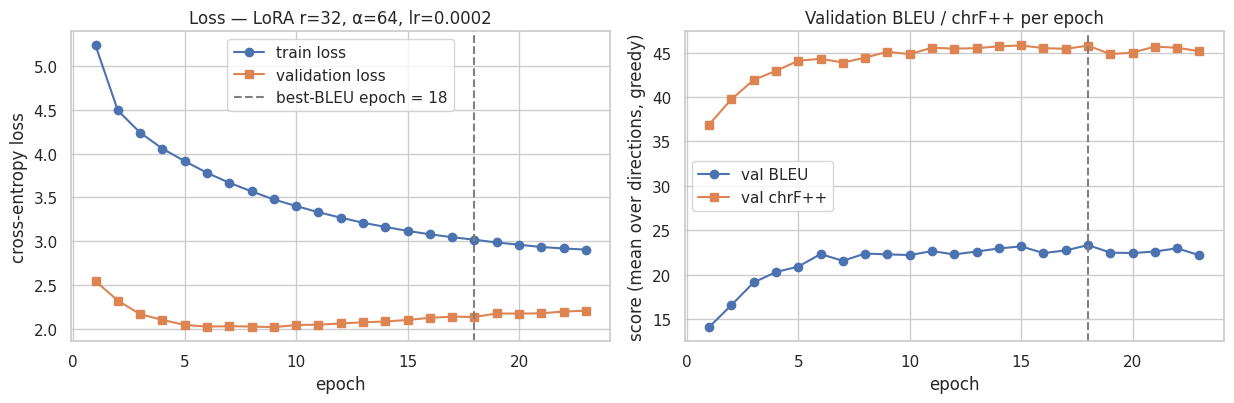

Best epoch 18 (BLEU 23.35): train loss 3.016 | val loss 2.134 | gap -0.882
Last epoch 23 (BLEU 22.19): train loss 2.903 | val loss 2.204
⚠️ Validation BLEU falls after the best epoch -> over-fitting; the best-BLEU weights were restored.


In [30]:
best = hist.loc[hist.val_BLEU.idxmax()]          # best epoch = highest validation BLEU (these are the weights that were restored)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax.plot(hist.epoch, hist.train_loss, "o-", label="train loss"); ax.plot(hist.epoch, hist.val_loss, "s-", label="validation loss")
ax.axvline(best.epoch, ls="--", c="gray", label=f"best-BLEU epoch = {int(best.epoch)}")
ax.set(xlabel="epoch", ylabel="cross-entropy loss", title=f"Loss — LoRA r={LORA_R}, α={LORA_ALPHA}, lr={LR}"); ax.legend()
ax2.plot(hist.epoch, hist.val_BLEU, "o-", label="val BLEU"); ax2.plot(hist.epoch, hist["val_chrF++"], "s-", label="val chrF++")
ax2.axvline(best.epoch, ls="--", c="gray")
ax2.set(xlabel="epoch", ylabel="score (mean over directions, greedy)", title="Validation BLEU / chrF++ per epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(f"{P2_DIR}/figures/loss_curves.png", dpi=150); plt.show()

last = hist.iloc[-1]
print(f"Best epoch {int(best.epoch)} (BLEU {best.val_BLEU:.2f}): train loss {best.train_loss:.3f} | val loss {best.val_loss:.3f} | gap {best.val_loss-best.train_loss:.3f}")
print(f"Last epoch {int(last.epoch)} (BLEU {last.val_BLEU:.2f}): train loss {last.train_loss:.3f} | val loss {last.val_loss:.3f}")
if last.epoch - best.epoch >= 3 and last.val_BLEU < best.val_BLEU - 1.0:
    print("⚠️ Validation BLEU falls after the best epoch -> over-fitting; the best-BLEU weights were restored.")
else:
    print("✅ No strong over-fitting signal in validation BLEU. (A rising validation LOSS alone is normal here and is not what the model is selected on.)")


### 2.3c Validation results: zero-shot vs. LoRA fine-tuned

,model,direction,n,BLEU,chrF++,TER
0,Zero-shot NLLB-600M,bcl_North → eng,236,12.08,32.81,86.80
1,Zero-shot NLLB-600M,eng → bcl_North,236,3.97,27.30,100.81
2,Zero-shot NLLB-600M,bcl_South → eng,236,15.91,36.44,80.92
3,Zero-shot NLLB-600M,eng → bcl_South,236,1.68,25.35,98.47
4,Zero-shot NLLB-600M,bcl_South → bcl_North,236,4.06,27.22,98.51
5,Zero-shot NLLB-600M,bcl_North → bcl_South,236,2.66,24.44,102.30
6,LoRA fine-tuned (best epoch),bcl_North → eng,236,27.41,45.04,63.79
7,LoRA fine-tuned (best epoch),eng → bcl_North,236,21.47,45.88,67.20
8,LoRA fine-tuned (best epoch),bcl_South → eng,236,27.23,46.76,59.61
9,LoRA fine-tuned (best epoch),eng → bcl_South,236,21.33,45.14,64.52


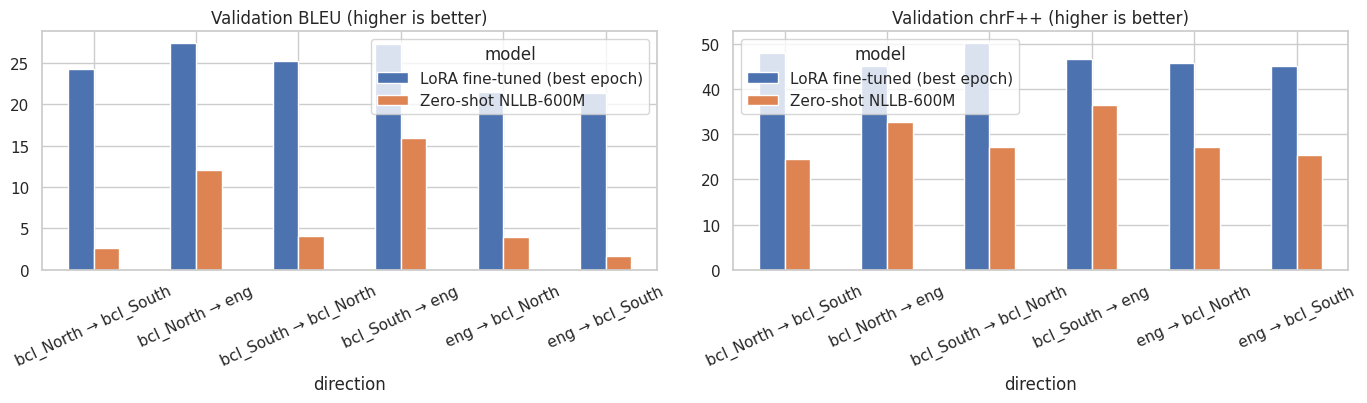

Mean validation BLEU over 6 directions: 24.47  (chrF++ 46.84, TER 63.17)


,direction,BLEU,95% CI low,95% CI high
0,bcl_North → eng,27.41,22.91,30.86
1,eng → bcl_North,21.47,18.35,24.72
2,bcl_South → eng,27.23,22.96,31.23
3,eng → bcl_South,21.33,18.28,24.60
4,bcl_South → bcl_North,25.16,22.06,28.44
5,bcl_North → bcl_South,24.23,20.86,27.12


Average 95% CI half-width: ±3.5 BLEU -> BLEU differences smaller than this between two models are not reliable.


,model,direction,n,BLEU,chrF++,TER
0,Copy source (no translation),bcl_South → bcl_North,236,15.49,46.04,70.43
1,Copy source (no translation),bcl_North → bcl_South,236,15.64,45.30,66.94


,direction,source,reference,zero_shot,lora
0,bcl_North → eng,Pagsugnad na daw ning tinugon.,Cook the rice now.,This sounds like an answer.,Please scratch your eyes.
1,bcl_North → eng,Tumunong ka!,Shut up!,Give it up!,Stop!
2,bcl_North → eng,Gumilid ka ta kung magilis ka.,"Move aside, you might get hit by a vehicle.",We'll move you if you're quick.,Smile when you smile.
3,bcl_North → eng,Tuho yu bado mo.,Your shirt has a hole in it.,Your clothes are clean.,Your clothes are so rough.
4,bcl_North → eng,Kalinupak man ning daran pagauran.,The road gets so muddy when it rains.,It's raining cats and dogs.,The heavy downpour is starting again.
236,eng → bcl_North,Cook the rice now.,Pagsugnad na daw ning tinugon.,Magluto ng rice ngayon.,Lutuon mo na yu bagas.
237,eng → bcl_North,Shut up!,Tumunong ka!,Huminto ka!,Hiluton mo na!
238,eng → bcl_North,"Move aside, you might get hit by a vehicle.",Gumilid ka ta kung magilis ka.,"Lumabas ka, baka saktan ka ng isang sasakyan.",Magliko ka ta mai ka makatama ning sasakyan.
239,eng → bcl_North,Your shirt has a hole in it.,Tuho yu bado mo.,May putok ang camiseta mo.,Ikan lugod yu bado mo.
240,eng → bcl_North,The road gets so muddy when it rains.,Kalinupak man ning daran pagauran.,Ang daan ay nagiging lubog kapag umuulan.,Malubak yang daran pag nag-uran.


In [31]:
ft_df, ft_preds = eval_model(model, "LoRA fine-tuned (best epoch)")
cmp = pd.concat([zs_df, ft_df], ignore_index=True)
display(cmp.round(2)); cmp.to_csv(f"{P2_DIR}/val_zero_shot_vs_lora.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax_, m in zip(axes, ["BLEU", "chrF++"]):
    cmp.pivot(index="direction", columns="model", values=m).plot.bar(rot=25, ax=ax_, title=f"Validation {m} (higher is better)")
plt.tight_layout(); plt.savefig(f"{P2_DIR}/figures/val_scores.png", dpi=150); plt.show()
print(f"Mean validation BLEU over {len(DIRECTIONS)} directions: {ft_df.BLEU.mean():.2f}  (chrF++ {ft_df['chrF++'].mean():.2f}, TER {ft_df.TER.mean():.2f})")

# how much does BLEU move just by chance? 95% bootstrap confidence interval over the validation sentences (236 per direction is small)
def bleu_ci(hyps, refs, n=500, seed=SEED):
    rs = np.random.default_rng(seed); N = len(hyps); vals = []
    for _ in range(n):
        idx = rs.integers(0, N, N)
        vals.append(sacrebleu.corpus_bleu([hyps[i] for i in idx], [[refs[i] for i in idx]]).score)
    return np.percentile(vals, [2.5, 97.5])
ci_rows = []
for d in DIRECTIONS:
    lab = f"{d[0]} → {d[1]}"; _, refs_, hf_ = ft_preds[d]; lo, hi = bleu_ci(hf_, refs_)
    ci_rows.append({"direction": lab, "BLEU": float(ft_df[ft_df.direction == lab].BLEU.iloc[0]), "95% CI low": lo, "95% CI high": hi})
ci_df = pd.DataFrame(ci_rows); display(ci_df.round(2)); ci_df.to_csv(f"{P2_DIR}/val_bleu_ci.csv", index=False)
print(f"Average 95% CI half-width: ±{((ci_df['95% CI high'] - ci_df['95% CI low']) / 2).mean():.1f} BLEU -> BLEU differences smaller than this between two models are not reliable.")

# honest reference for the Bikol<->Bikol directions: how well does simply COPYING the source do? The model must beat this.
copy_df = pd.DataFrame([{"model": "Copy source (no translation)", "direction": f"{s} → {t}", "n": len(rows),
                         **score([r["src"] for r in rows], [r["tgt"] for r in rows])}
                        for (s, t), rows in VAL_BY_DIR.items() if "eng" not in (s, t)])
if len(copy_df): display(copy_df.round(2)); copy_df.to_csv(f"{P2_DIR}/val_copy_baseline.csv", index=False)

# side-by-side predictions
rows = []
for d in DIRECTIONS:
    srcs, refs, hz = zs_preds[d]; _, _, hf = ft_preds[d]
    rows += [{"direction": f"{d[0]} → {d[1]}", "source": s, "reference": r, "zero_shot": z, "lora": f} for s, r, z, f in zip(srcs, refs, hz, hf)]
preds_df = pd.DataFrame(rows); preds_df.to_csv(f"{P2_DIR}/val_predictions.csv", index=False)
pd.set_option("display.max_colwidth", 80)
display(preds_df.groupby("direction").head(5))

### 2.3c-bis Underfitting check (can the model reproduce its own training data?)
In v3 the gap was 32–49 chrF++ points (train 82–95, validation 45–51), i.e. over-fitting. v4's regularisation aims to shrink it. In v2 the restored epoch could not reproduce its own training sentences (train-row chrF++ 54–66, exact match 5–29 %), which is the signature of an under-fitted model. This cell measures it on 150 training sentences per direction for the v3 model; selecting by BLEU and training on more data should raise it.


In [32]:
# ---- Underfitting check: can the model reproduce sentences it was TRAINED on? ----
# If chrF++ on training rows is low, the adapter is too small / under-trained.  A big train>>val gap means over-fitting instead.
def eval_train_subset(model, label, n=150):
    rs = np.random.default_rng(SEED); out = []
    for d in DIRECTIONS:
        rows = [r for r in train_rows if (r["src_lang"], r["tgt_lang"]) == d]
        pick = [rows[i] for i in rs.choice(len(rows), size=min(n, len(rows)), replace=False)]
        hyps = translate(model, [r["src"] for r in pick], d[0], d[1])
        sc = score(hyps, [r["tgt"] for r in pick])
        exact = float(np.mean([h.strip().lower() == r["tgt"].strip().lower() for h, r in zip(hyps, pick)]))
        out.append({"model": label, "direction": f"{d[0]} → {d[1]}", "n": len(pick), "chrF++ (train rows)": sc["chrF++"],
                    "BLEU (train rows)": sc["BLEU"], "exact-match %": 100 * exact})
    return pd.DataFrame(out)

fit_df = eval_train_subset(model, "LoRA fine-tuned (best epoch)")
chk = fit_df.merge(ft_df[["direction", "chrF++"]].rename(columns={"chrF++": "chrF++ (val)"}), on="direction")
chk["train-val chrF++ gap"] = chk["chrF++ (train rows)"] - chk["chrF++ (val)"]
display(chk.round(2)); chk.to_csv(f"{P2_DIR}/underfit_check.csv", index=False)
if (chk["chrF++ (train rows)"] < 70).any():
    print("⚠️ UNDERFITTING: chrF++ on training sentences is < 70 -> raise LORA_R / add target modules / train longer / raise LR.")
elif (chk["train-val chrF++ gap"] > 35).any():
    print("⚠️ OVER-FITTING: the model memorises training rows but does not generalise -> more dropout, lower r, or more data.")
else:
    print("✅ The adapter has enough capacity to fit the training data and the train/val gap is moderate.")

,model,direction,n,chrF++ (train rows),BLEU (train rows),exact-match %,chrF++ (val),train-val chrF++ gap
0,LoRA fine-tuned (best epoch),bcl_North → eng,150,95.32,93.25,83.33,45.04,50.28
1,LoRA fine-tuned (best epoch),eng → bcl_North,150,85.54,77.55,54.00,45.88,39.66
2,LoRA fine-tuned (best epoch),bcl_South → eng,150,93.20,90.91,80.00,46.76,46.44
3,LoRA fine-tuned (best epoch),eng → bcl_South,150,87.47,79.41,58.67,45.14,42.33
4,LoRA fine-tuned (best epoch),bcl_South → bcl_North,150,79.38,67.52,42.67,50.29,29.09
5,LoRA fine-tuned (best epoch),bcl_North → bcl_South,150,78.21,65.08,40.00,47.94,30.27


⚠️ OVER-FITTING: the model memorises training rows but does not generalise -> more dropout, lower r, or more data.


### 2.3d (optional) Hyper-parameter sweep: capacity (r, α, target modules)
Off by default (≈ 4 × 6 min on a T4). Compares attention-only LoRA against attention+FFN LoRA at r = 16 / 32 / 64, ranked by **best validation loss** (and validation chrF++ on 100 sentences/direction). If another combination wins, change `LORA_R` / `LORA_ALPHA` / `TARGET_MODULES` in the config and re-run from 2.3.

In [33]:
ATTN = ["q_proj", "v_proj"]; ALL = ["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"]
RUN_SWEEP, SWEEP_EPOCHS = False, 12
SWEEP_GRID = [(16, 32, ATTN), (16, 32, ALL), (32, 64, ALL), (64, 128, ALL)]   # (r, alpha, target_modules)

if RUN_SWEEP:
    sweep = []
    for r, a, tm in SWEEP_GRID:
        d = f"{P2_DIR}/sweep/r{r}_a{a}_{len(tm)}mods"
        m, t, h = train_lora(r, a, epochs=SWEEP_EPOCHS, out_dir=d, verbose=False, targets=tm)
        e, _ = eval_model(m, f"r={r},a={a},{len(tm)}mods", limit=100)
        b = h.loc[h.val_BLEU.idxmax()]
        sweep.append({"r": r, "alpha": a, "modules": ",".join(tm), "trainable_params": sum(p.numel() for p in m.parameters() if p.requires_grad),
                      "best_epoch": int(b.epoch), "train_loss@best": b.train_loss, "best_val_loss": b.val_loss, "best_val_BLEU": b.val_BLEU,
                      "val_chrF++": e["chrF++"].mean()})
        del m, t; shutil.rmtree(d, ignore_errors=True); gc.collect(); torch.cuda.empty_cache()
    sweep_df = pd.DataFrame(sweep).sort_values("best_val_BLEU", ascending=False); display(sweep_df.round(4))
    sweep_df.to_csv(f"{P2_DIR}/lora_sweep.csv", index=False)
else:
    print("Sweep skipped (set RUN_SWEEP=True to run).")

Sweep skipped (set RUN_SWEEP=True to run).


## 2.4 Quantization & Model Export
Four deployable variants are built and benchmarked on **validation** sentences (model time only, per single sentence — the setting a web API sees):

| Variant | What it is |
|---|---|
| **A** | Base model + **LoRA adapter loaded dynamically** (unmerged, GPU, AMP) |
| **B** | Adapter **merged** into the base weights (fp32 + AMP, GPU) — no LoRA overhead |
| **C** | Merged, **fp16** (GPU) — also saved as a standalone model |
| **D** | Merged, **dynamic int8 quantization** of all Linear layers (CPU) — for GPU-less deployment |

The adapter (r=32, all attention + FFN linears) is ≈ 70 MB in fp32; set `LORA_R = 16` for ≈ 35 MB.


In [34]:
ADAPTER_DIR, MERGED_DIR = f"{P2_DIR}/lora_adapter", f"{P2_DIR}/merged_fp16"
def dir_mb(p): return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / 1e6

model.save_pretrained(ADAPTER_DIR); tokenizer.save_pretrained(ADAPTER_DIR)
meta = {"base_model": MODEL_NAME, "run_name": RUN_NAME, "directions": DIRECTIONS, "language_code_map": CODE, "max_len": MAX_LEN,
        "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT, "target_modules": TARGET_MODULES},
        "training": {"lr": LR, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "seed": SEED, "best_epoch": int(best.epoch), "best_val_BLEU": float(best.val_BLEU), "label_smoothing": LABEL_SMOOTHING, "src_token_dropout": SRC_TOKEN_DROPOUT, "weight_decay": WEIGHT_DECAY, "lora_dropout": LORA_DROPOUT,
                     "best_val_loss": float(best.val_loss)}}
json.dump(meta, open(f"{ADAPTER_DIR}/bikol_meta.json", "w"), indent=2)
adapter_mb = sum(os.path.getsize(f"{ADAPTER_DIR}/{f}") for f in os.listdir(ADAPTER_DIR) if f.startswith("adapter_model"))/1e6
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Adapter saved -> {ADAPTER_DIR}\n   adapter weights: {adapter_mb:.1f} MB | trainable params: {n_train:,}")

del model, trainer; gc.collect(); torch.cuda.empty_cache()     # free GPU before the export tests

✅ Adapter saved -> phase2_outputs/multi/lora_adapter
   adapter weights: 69.3 MB | trainable params: 17,301,504


In [35]:
# ---------------- benchmark helpers ----------------
N_LAT, N_LAT_CPU, N_QUALITY = 60, 15, 60
src_l, tgt_l = DIRECTIONS[0]
_val0 = VAL_BY_DIR[DIRECTIONS[0]]
_rs = np.random.default_rng(SEED)
LAT_TEXTS = [_val0[i]["src"] for i in _rs.choice(len(_val0), size=min(N_LAT, len(_val0)), replace=False)]
Q_SRC, Q_REF = [r["src"] for r in _val0[:N_QUALITY]], [r["tgt"] for r in _val0[:N_QUALITY]]

def bench(model, device, amp_on, texts, num_beams, n_warm=2):
    model.eval(); forced = tokenizer.convert_tokens_to_ids(CODE[tgt_l]); tokenizer.src_lang = CODE[src_l]
    def run(t):
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        enc = tokenizer(t, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
            g = model.generate(**enc, forced_bos_token_id=forced, num_beams=num_beams, max_new_tokens=96)
        if device == "cuda": torch.cuda.synchronize()
        return (time.perf_counter() - t0) * 1000, g.shape[1]
    for t in texts[:n_warm]: run(t)
    recs = []
    for t in texts:
        ms, nout = run(t)
        recs.append({"src_tokens": len(tokenizer(t, add_special_tokens=False)["input_ids"]), "ms": ms, "out_tokens": nout})
    return pd.DataFrame(recs)

SUMMARY, LAT_RECORDS = [], []
def evaluate_variant(name, model, device, amp_on, size_mb, n_lat):
    texts = LAT_TEXTS[:n_lat]
    g = bench(model, device, amp_on, texts, num_beams=1)
    b = bench(model, device, amp_on, texts, num_beams=4)
    hyps = translate(model, Q_SRC, src_l, tgt_l, num_beams=4, bs=16, device=device, amp_on=amp_on)
    sc = score(hyps, Q_REF)
    for mode, d in (("greedy", g), ("beam4", b)):
        LAT_RECORDS.append(d.assign(variant=name, mode=mode))
    SUMMARY.append({"variant": name, "size_MB": round(size_mb, 1), "latency_greedy_ms": g.ms.mean(), "p95_greedy_ms": g.ms.quantile(.95),
                    "latency_beam4_ms": b.ms.mean(), "chrF++": sc["chrF++"], "BLEU": sc["BLEU"], "TER": sc["TER"],
                    f"greedy<300ms": bool(g.ms.mean() < 300)})
    print(f"{name}: greedy {g.ms.mean():.0f} ms | beam4 {b.ms.mean():.0f} ms | chrF++ {sc['chrF++']:.1f}")

In [36]:
# ---- A: base + adapter loaded dynamically (also proves the saved adapter reloads correctly) ----
dyn = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), ADAPTER_DIR).to(DEVICE).eval()
evaluate_variant("A: base + LoRA adapter (unmerged, GPU)", dyn, DEVICE, True, adapter_mb, N_LAT)

# ---- B: merge the adapter into the weights ----
merged = dyn.merge_and_unload().eval()
evaluate_variant("B: merged fp32 (GPU, AMP)", merged, DEVICE, True, 2460, N_LAT)

# ---- C: fp16 standalone model ----
half = copy.deepcopy(merged).half().eval()
half.save_pretrained(MERGED_DIR); tokenizer.save_pretrained(MERGED_DIR)
evaluate_variant("C: merged fp16 (GPU)", half, DEVICE, False, dir_mb(MERGED_DIR), N_LAT)
print(f"merged fp16 model saved -> {MERGED_DIR} ({dir_mb(MERGED_DIR):.0f} MB)")

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

A: base + LoRA adapter (unmerged, GPU): greedy 561 ms | beam4 715 ms | chrF++ 44.3
B: merged fp32 (GPU, AMP): greedy 298 ms | beam4 368 ms | chrF++ 44.2


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C: merged fp16 (GPU): greedy 178 ms | beam4 228 ms | chrF++ 44.2
merged fp16 model saved -> phase2_outputs/multi/merged_fp16 (1262 MB)


In [37]:
# ---- D: dynamic int8 quantization (CPU) ----
RUN_CPU_INT8 = True
if RUN_CPU_INT8:
    try:
        cpu32 = copy.deepcopy(merged).float().cpu().eval()
        q8 = torch.ao.quantization.quantize_dynamic(cpu32, {torch.nn.Linear}, dtype=torch.qint8)
        q8_path = f"{P2_DIR}/merged_int8_state_dict.pt"; torch.save(q8.state_dict(), q8_path)
        evaluate_variant("D: merged int8 (CPU)", q8, "cpu", False, os.path.getsize(q8_path) / 1e6, N_LAT_CPU)
        del cpu32, q8
    except Exception as e:
        print("⚠️ int8 quantization/benchmark failed:", type(e).__name__, str(e)[:200])

D: merged int8 (CPU): greedy 732 ms | beam4 1024 ms | chrF++ 42.6


### 2.4b Benchmark results: size · latency · quality (validation subset)

,variant,size_MB,latency_greedy_ms,p95_greedy_ms,latency_beam4_ms,chrF++,BLEU,TER,greedy<300ms
0,"A: base + LoRA adapter (unmerged, GPU)",69.3,561.1,841.9,715.4,44.3,25.4,72.6,False
1,"B: merged fp32 (GPU, AMP)",2460.0,297.8,437.2,368.3,44.2,25.5,72.6,True
2,C: merged fp16 (GPU),1262.5,178.0,268.7,227.8,44.2,25.5,72.6,True
3,D: merged int8 (CPU),1666.0,732.4,1052.1,1024.2,42.6,23.0,71.3,False


Mean latency (ms) by source length in tokens — greedy decoding:


length_bucket,≤6,7–10,11–14,15–20,>20
variant,,,,,
"A: base + LoRA adapter (unmerged, GPU)",389.0,474.0,550.0,687.0,789.0
"B: merged fp32 (GPU, AMP)",206.0,254.0,304.0,348.0,415.0
C: merged fp16 (GPU),122.0,148.0,176.0,221.0,249.0
D: merged int8 (CPU),604.0,650.0,691.0,962.0,NaN


… beam search (4 beams):


length_bucket,≤6,7–10,11–14,15–20,>20
variant,,,,,
"A: base + LoRA adapter (unmerged, GPU)",452.0,556.0,615.0,1114.0,946.0
"B: merged fp32 (GPU, AMP)",232.0,280.0,345.0,562.0,475.0
C: merged fp16 (GPU),148.0,177.0,198.0,350.0,303.0
D: merged int8 (CPU),782.0,938.0,1033.0,1291.0,NaN


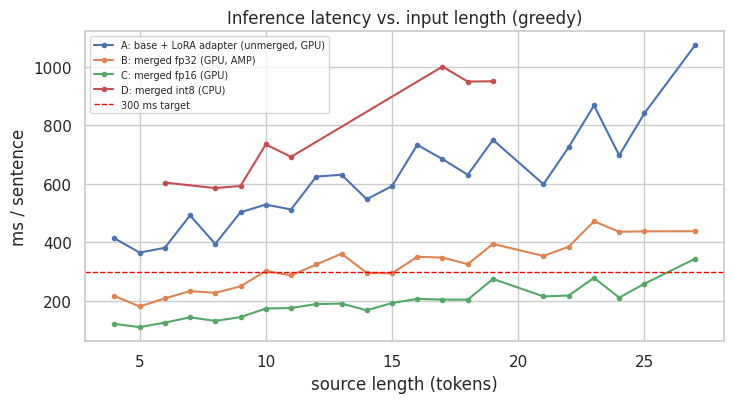

➡️ Best variant meeting the <300 ms greedy target: B: merged fp32 (GPU, AMP) (chrF++ 44.2, 298 ms)


In [38]:
summ = pd.DataFrame(SUMMARY); display(summ.round(1))
summ.to_csv(f"{P2_DIR}/export_benchmark.csv", index=False)

lat = pd.concat(LAT_RECORDS, ignore_index=True)
lat["length_bucket"] = pd.cut(lat.src_tokens, [0, 6, 10, 14, 20, 1000], labels=["≤6", "7–10", "11–14", "15–20", ">20"])
tab = lat[lat["mode"] == "greedy"].pivot_table(index="variant", columns="length_bucket", values="ms", aggfunc="mean").round(0)
print("Mean latency (ms) by source length in tokens — greedy decoding:"); display(tab)
tab.to_csv(f"{P2_DIR}/latency_by_length_greedy.csv")
tab_b = lat[lat["mode"] == "beam4"].pivot_table(index="variant", columns="length_bucket", values="ms", aggfunc="mean").round(0)
print("… beam search (4 beams):"); display(tab_b); tab_b.to_csv(f"{P2_DIR}/latency_by_length_beam4.csv")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for v, d in lat[lat["mode"] == "greedy"].groupby("variant"):
    g = d.groupby("src_tokens").ms.mean(); ax.plot(g.index, g.values, "o-", ms=3, label=v)
ax.axhline(300, c="red", ls="--", lw=1, label="300 ms target")
ax.set(xlabel="source length (tokens)", ylabel="ms / sentence", title="Inference latency vs. input length (greedy)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{P2_DIR}/figures/latency_vs_length.png", dpi=150); plt.show()

ok = summ[summ["greedy<300ms"]]
if len(ok):
    pick = ok.sort_values("chrF++", ascending=False).iloc[0]
    print(f"➡️ Best variant meeting the <300 ms greedy target: {pick.variant} (chrF++ {pick['chrF++']:.1f}, {pick.latency_greedy_ms:.0f} ms)")
else:
    print("⚠️ No variant met the 300 ms target in greedy mode on this hardware.")

### 2.4c Hand-off to Phase 3 (API): loader + translation with confidence score
Phase 3's `POST /api/v1/translate` needs `translated_text`, `confidence_score` and `inference_latency_ms`. The helper below returns exactly those (confidence = geometric-mean token probability of the beam-search output).

In [39]:
def load_for_inference(adapter_dir=ADAPTER_DIR, merge=True, device=DEVICE):
    tok_ = AutoTokenizer.from_pretrained(adapter_dir)
    m = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), adapter_dir)
    m = m.merge_and_unload() if merge else m
    return tok_, m.to(device).eval()

@torch.no_grad()
def translate_with_confidence(model, text, src_lang, tgt_lang, num_beams=4, device=DEVICE, amp_on=True):
    tokenizer.src_lang = CODE[src_lang]
    t0 = time.perf_counter()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
        out = model.generate(**enc, forced_bos_token_id=tokenizer.convert_tokens_to_ids(CODE[tgt_lang]), num_beams=num_beams,
                             max_new_tokens=96, return_dict_in_generate=True, output_scores=True)
    ms = (time.perf_counter() - t0) * 1000
    conf = float(torch.exp(out.sequences_scores[0])) if getattr(out, "sequences_scores", None) is not None else None
    return {"status": "success", "translated_text": tokenizer.decode(out.sequences[0], skip_special_tokens=True),
            "confidence_score": None if conf is None else round(conf, 2), "inference_latency_ms": round(ms)}

demo_src = {"bcl_North": "Mai mo na siya paghamason.", "bcl_South": "Dai mo na sya paghabulon.", "eng": "Where are you going?"}[PAIR[0]]
print(translate_with_confidence(merged, demo_src, PAIR[0], PAIR[1]))
print(translate_with_confidence(merged, val_rows[5]["src"], val_rows[5]["src_lang"], val_rows[5]["tgt_lang"]), "| ref:", val_rows[5]["tgt"])
if ("bcl_South", "bcl_North") in DIRECTIONS:        # cross-dialect demo (South -> North)
    print(translate_with_confidence(merged, "Dai mo na sya paghabulon.", "bcl_South", "bcl_North"))


{'status': 'success', 'translated_text': "Don't chase after him/her anymore.", 'confidence_score': 0.81, 'inference_latency_ms': 412}
{'status': 'success', 'translated_text': 'That person is crazy!', 'confidence_score': 0.62, 'inference_latency_ms': 198} | ref: So conceited!
{'status': 'success', 'translated_text': 'Mai mo na siya paghamason.', 'confidence_score': 0.68, 'inference_latency_ms': 275}


In [40]:
if PUSH_TO_HUB:
    from huggingface_hub import notebook_login; notebook_login()
    peft_m = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), ADAPTER_DIR)
    peft_m.push_to_hub(HF_REPO); tokenizer.push_to_hub(HF_REPO)
    print("Pushed to https://huggingface.co/" + HF_REPO)

# zip the small deliverables (adapter + reports + figures). The big merged models stay in the folder.
Z2 = f"phase2_{RUN_NAME}_deliverables.zip"
with zipfile.ZipFile(Z2, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(P2_DIR):
        if any(s in root for s in ("checkpoints", "merged_fp16", "sweep")): continue
        for f in fs:
            if f.endswith("int8_state_dict.pt"): continue
            z.write(os.path.join(root, f))
print("Created", Z2, f"({os.path.getsize(Z2)/1e6:.1f} MB)")
try:
    from google.colab import files as colab_files; colab_files.download(Z2)
except ImportError:
    pass

Created phase2_multi_deliverables.zip (70.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### What to put in your README / report for Phase 2
* **Model choice** (2.1 table) and the **proxy-language-code** decision (`tgl_Latn` North, `war_Latn` South, `eng_Latn`) with its consequence: one adapter serves all six directions.
* **LoRA config & trainable-parameter count** (`bikol_meta.json`), hyper-parameters, seed, hardware, training time.
* **Loss and BLEU curves** (`figures/loss_curves.png`) and your over-fitting discussion; the optional sweep table (`lora_sweep.csv`).
* **Validation** zero-shot vs. LoRA table (`val_zero_shot_vs_lora.csv`), the **copy-source baseline** for South↔North (`val_copy_baseline.csv`) — the final test-set numbers come in Phase 4.
* **Ablation**: run `"ablation_eng_only"` as well to show what adding South↔North changes.
* **Export benchmark** (`export_benchmark.csv`, `latency_by_length_*.csv`) — the "latency table (inference time per token length)" deliverable.
* To train automatically, use section **2.5**. To train by hand, set `RUN_NAME` in the config and run 2.1–2.4.


---
## 2.5 Train & export in one go
Runs the whole Phase 2 pipeline (2.1 → 2.4: data → zero-shot baseline → LoRA training → curves → validation → export & benchmark) for each run listed in `RUN_NAMES`. The default run **`multi`** trains **one adapter on all six directions (English↔North, English↔South, South↔North)**:

`phase2_outputs/multi/`

**Before you run it:** run the **2.0 setup cells and the config cell**. You do *not* need to run 2.1–2.4 by hand first — the loop does it.

⏱ Expect roughly 30–60 min on a T4 (≈ 3× more examples per epoch than v2). Use `USE_DRIVE = True` in the config so progress survives a Colab disconnect; re-running the cell then resumes from the last checkpoint.


In [41]:
RUN_NAMES          = ["multi"]   # "multi" = ONE regularised adapter, 6 directions.  Add "multi_v3_baseline" to re-measure the old settings, "ablation_eng_only" to drop South<->North.
SKIP_IF_DONE       = False       # skip a run whose adapter + benchmark already exist
RESUME_IF_POSSIBLE = True        # resume an UNFINISHED run (checkpoints exist, no train_done.json) from its last checkpoint


▶  run 'multi'  |  6 directions  |  outputs -> phase2_outputs/multi
train examples: 6582 | val examples: 1416   (test set intentionally NOT loaded)
{'src_lang': 'bcl_North', 'tgt_lang': 'eng', 'src': 'Layalaya ko sa biyaheng ibisag yan.', 'tgt': 'I got extremely dizzy from the trip.'}
{'src_lang': 'bcl_North', 'tgt_lang': 'eng', 'src': 'Mai mo na siya paghamason.', 'tgt': "Don't chase after him/her anymore."}
{'src_lang': 'bcl_North', 'tgt_lang': 'eng', 'src': 'Pagtungog daw sa langag!', 'tgt': 'Stay in the house!'}
source tokens: mean 12.4, p95 21, max 35 | target tokens: mean 12.4, p95 21, max 35
examples hitting MAX_LEN=64 (truncated): 0

Example encoding:
 input : ['tgl_Latn', '▁L', 'aya', 'laya', '▁ko', '▁sa', '▁bi', 'yah', 'eng', '▁ibis', 'ag', '▁yan', '.', '</s>']
 labels: ['eng_Latn', '▁I', '▁got', '▁extremely', '▁di', 'zzy', '▁from', '▁the', '▁trip', '.', '</s>']


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

,model,direction,n,BLEU,chrF++,TER
0,Zero-shot NLLB-600M,bcl_North → eng,236,12.08,32.81,86.80
1,Zero-shot NLLB-600M,eng → bcl_North,236,3.97,27.30,100.81
2,Zero-shot NLLB-600M,bcl_South → eng,236,15.91,36.44,80.92
3,Zero-shot NLLB-600M,eng → bcl_South,236,1.68,25.35,98.47
4,Zero-shot NLLB-600M,bcl_South → bcl_North,236,4.06,27.22,98.51
5,Zero-shot NLLB-600M,bcl_North → bcl_South,236,2.66,24.44,102.30


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360
192 LoRA-wrapped linear layers, e.g.:
  base_model.model.model.encoder.layers.0.self_attn.k_proj.lora_A
  base_model.model.model.encoder.layers.0.self_attn.v_proj.lora_A
  base_model.model.model.encoder.layers.0.self_attn.q_proj.lora_A
✅ only LoRA weights are trainable; base model is frozen
steps/epoch: 412 | max total: 12360


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360
   [epoch 1] val BLEU 14.12 | chrF++ 36.90  (mean over 6 directions, greedy)  | best 14.12 @ epoch 1
{'loss': '5.235', 'grad_norm': '2.219', 'learning_rate': '0.0001109', 'epoch': '1'}
{'eval_loss': '2.542', 'eval_runtime': '6.709', 'eval_samples_per_second': '211.1', 'eval_steps_per_second': '6.708', 'epoch': '1'}
   [epoch 2] val BLEU 16.60 | chrF++ 39.75  (mean over 6 directions, greedy)  | best 16.60 @ epoch 2
{'loss': '4.493', 'grad_norm': '3.286', 'learning_rate': '0.0001986', 'epoch': '2'}
{'eval_loss': '2.321', 'eval_runtime': '6.942', 'eval_samples_per_second': '204', 'eval_steps_per_second': '6.482', 'epoch': '2'}
   [epoch 3] val BLEU 19.15 | chrF++ 41.92  (mean over 6 directions, greedy)  | best 19.15 @ epoch 3
{'loss': '4.239', 'grad_norm': '2.742', 'learning_rate': '0.0001915', 'epoch': '3'}
{'eval_loss': '2.165', 'eval_runtime': '6.702', 'eval_samples_per_second': '211.3', 'eval_steps_per_secon

,epoch,train_loss,val_loss,val_BLEU,val_chrF++
0,1,5.2354,2.5422,14.1157,36.9036
1,2,4.4926,2.3208,16.5963,39.7543
2,3,4.2394,2.1649,19.1464,41.9212
3,4,4.0562,2.0998,20.3134,42.9485
4,5,3.9136,2.0427,20.9284,44.0744
5,6,3.7800,2.0232,22.3347,44.3034
6,7,3.6662,2.0281,21.5845,43.8848
7,8,3.5687,2.0243,22.3890,44.4290
8,9,3.4754,2.0169,22.3068,45.0930
9,10,3.4007,2.0415,22.2253,44.8227


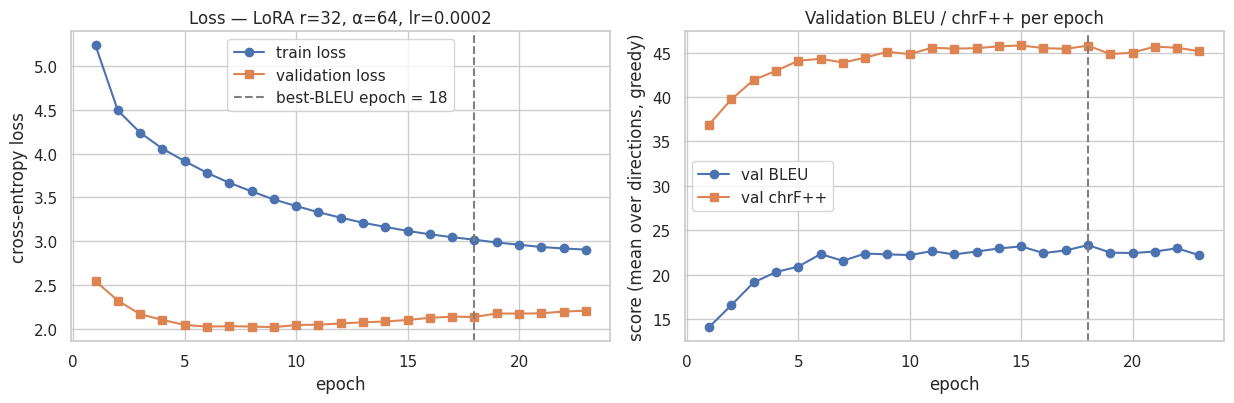

Best epoch 18 (BLEU 23.35): train loss 3.016 | val loss 2.134 | gap -0.882
Last epoch 23 (BLEU 22.19): train loss 2.903 | val loss 2.204
⚠️ Validation BLEU falls after the best epoch -> over-fitting; the best-BLEU weights were restored.


,model,direction,n,BLEU,chrF++,TER
0,Zero-shot NLLB-600M,bcl_North → eng,236,12.08,32.81,86.80
1,Zero-shot NLLB-600M,eng → bcl_North,236,3.97,27.30,100.81
2,Zero-shot NLLB-600M,bcl_South → eng,236,15.91,36.44,80.92
3,Zero-shot NLLB-600M,eng → bcl_South,236,1.68,25.35,98.47
4,Zero-shot NLLB-600M,bcl_South → bcl_North,236,4.06,27.22,98.51
5,Zero-shot NLLB-600M,bcl_North → bcl_South,236,2.66,24.44,102.30
6,LoRA fine-tuned (best epoch),bcl_North → eng,236,27.41,45.04,63.79
7,LoRA fine-tuned (best epoch),eng → bcl_North,236,21.47,45.88,67.20
8,LoRA fine-tuned (best epoch),bcl_South → eng,236,27.23,46.76,59.61
9,LoRA fine-tuned (best epoch),eng → bcl_South,236,21.33,45.14,64.52


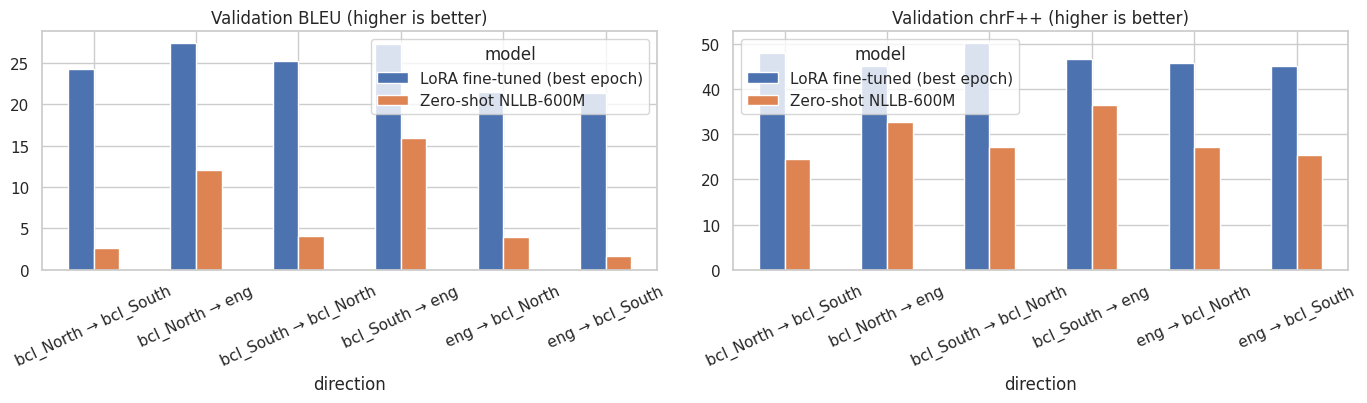

Mean validation BLEU over 6 directions: 24.47  (chrF++ 46.84, TER 63.17)


,direction,BLEU,95% CI low,95% CI high
0,bcl_North → eng,27.41,22.91,30.86
1,eng → bcl_North,21.47,18.35,24.72
2,bcl_South → eng,27.23,22.96,31.23
3,eng → bcl_South,21.33,18.28,24.60
4,bcl_South → bcl_North,25.16,22.06,28.44
5,bcl_North → bcl_South,24.23,20.86,27.12


Average 95% CI half-width: ±3.5 BLEU -> BLEU differences smaller than this between two models are not reliable.


,model,direction,n,BLEU,chrF++,TER
0,Copy source (no translation),bcl_South → bcl_North,236,15.49,46.04,70.43
1,Copy source (no translation),bcl_North → bcl_South,236,15.64,45.30,66.94


,direction,source,reference,zero_shot,lora
0,bcl_North → eng,Pagsugnad na daw ning tinugon.,Cook the rice now.,This sounds like an answer.,Please scratch your eyes.
1,bcl_North → eng,Tumunong ka!,Shut up!,Give it up!,Stop!
2,bcl_North → eng,Gumilid ka ta kung magilis ka.,"Move aside, you might get hit by a vehicle.",We'll move you if you're quick.,Smile when you smile.
3,bcl_North → eng,Tuho yu bado mo.,Your shirt has a hole in it.,Your clothes are clean.,Your clothes are so rough.
4,bcl_North → eng,Kalinupak man ning daran pagauran.,The road gets so muddy when it rains.,It's raining cats and dogs.,The heavy downpour is starting again.
236,eng → bcl_North,Cook the rice now.,Pagsugnad na daw ning tinugon.,Magluto ng rice ngayon.,Lutuon mo na yu bagas.
237,eng → bcl_North,Shut up!,Tumunong ka!,Huminto ka!,Hiluton mo na!
238,eng → bcl_North,"Move aside, you might get hit by a vehicle.",Gumilid ka ta kung magilis ka.,"Lumabas ka, baka saktan ka ng isang sasakyan.",Magliko ka ta mai ka makatama ning sasakyan.
239,eng → bcl_North,Your shirt has a hole in it.,Tuho yu bado mo.,May putok ang camiseta mo.,Ikan lugod yu bado mo.
240,eng → bcl_North,The road gets so muddy when it rains.,Kalinupak man ning daran pagauran.,Ang daan ay nagiging lubog kapag umuulan.,Malubak yang daran pag nag-uran.


,model,direction,n,chrF++ (train rows),BLEU (train rows),exact-match %,chrF++ (val),train-val chrF++ gap
0,LoRA fine-tuned (best epoch),bcl_North → eng,150,95.32,93.25,83.33,45.04,50.28
1,LoRA fine-tuned (best epoch),eng → bcl_North,150,85.54,77.55,54.00,45.88,39.66
2,LoRA fine-tuned (best epoch),bcl_South → eng,150,93.20,90.91,80.00,46.76,46.44
3,LoRA fine-tuned (best epoch),eng → bcl_South,150,87.47,79.41,58.67,45.14,42.33
4,LoRA fine-tuned (best epoch),bcl_South → bcl_North,150,79.38,67.52,42.67,50.29,29.09
5,LoRA fine-tuned (best epoch),bcl_North → bcl_South,150,78.21,65.08,40.00,47.94,30.27


... (6 outputs left out)

Mean latency (ms) by source length in tokens — greedy decoding:


length_bucket,≤6,7–10,11–14,15–20,>20
variant,,,,,
"A: base + LoRA adapter (unmerged, GPU)",405.0,468.0,542.0,661.0,776.0
"B: merged fp32 (GPU, AMP)",203.0,258.0,312.0,353.0,432.0
C: merged fp16 (GPU),126.0,146.0,172.0,218.0,238.0
D: merged int8 (CPU),511.0,597.0,663.0,893.0,NaN


… beam search (4 beams):


length_bucket,≤6,7–10,11–14,15–20,>20
variant,,,,,
"A: base + LoRA adapter (unmerged, GPU)",497.0,556.0,658.0,1071.0,927.0
"B: merged fp32 (GPU, AMP)",248.0,299.0,347.0,582.0,512.0
C: merged fp16 (GPU),159.0,184.0,200.0,347.0,279.0
D: merged int8 (CPU),812.0,934.0,1091.0,1243.0,NaN


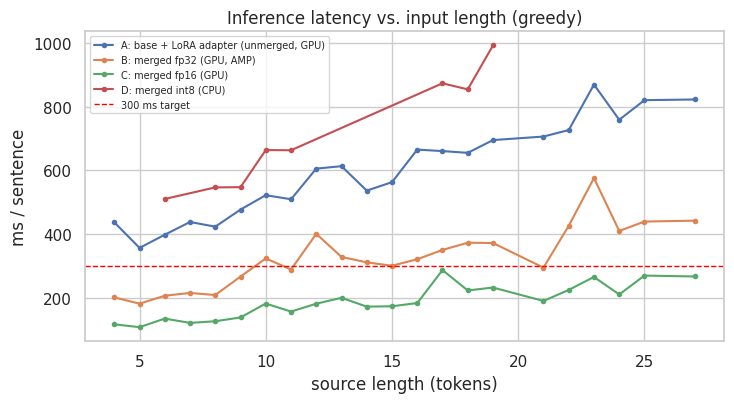

➡️ Best variant meeting the <300 ms greedy target: C: merged fp16 (GPU) (chrF++ 44.2, 175 ms)
{'status': 'success', 'translated_text': "Don't chase after him/her anymore.", 'confidence_score': 0.81, 'inference_latency_ms': 480}
{'status': 'success', 'translated_text': 'That person is crazy!', 'confidence_score': 0.62, 'inference_latency_ms': 230} | ref: So conceited!
{'status': 'success', 'translated_text': 'Mai mo na siya paghamason.', 'confidence_score': 0.68, 'inference_latency_ms': 327}
Created phase2_multi_deliverables.zip (70.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Status: {'multi': 'done'}


In [42]:
#@title 2.5b Runner — loops over the runs (code hidden; double-click to view) { display-mode: "form" }
import traceback, glob
PIPELINE = [
r'''
# ---- make sure the Phase 1 outputs exist (works also when Phase 2 is run in a fresh session) ----
P1_DIR = OUT_DIR if "OUT_DIR" in globals() else "phase1_outputs"
if not os.path.isdir(f"{P1_DIR}/directional"):
    if not os.path.exists("phase1_outputs.zip"):
        try:
            from google.colab import files as _f
            print("Upload phase1_outputs.zip (created at the end of Phase 1) ...")
            _f.upload()
        except ImportError:
            raise FileNotFoundError("phase1_outputs/ not found — run Phase 1 first")
    zipfile.ZipFile("phase1_outputs.zip").extractall(".")
    P1_DIR = "phase1_outputs"

def read_jsonl(path):
    with open(path, encoding="utf-8") as f: return [json.loads(l) for l in f]

train_rows  = [r for s, t in DIRECTIONS for r in read_jsonl(f"{P1_DIR}/directional/train.{s}-{t}.jsonl")]
VAL_BY_DIR  = {d: read_jsonl(f"{P1_DIR}/directional/val.{d[0]}-{d[1]}.jsonl") for d in DIRECTIONS}
val_rows    = [r for rows in VAL_BY_DIR.values() for r in rows]
print(f"train examples: {len(train_rows)} | val examples: {len(val_rows)}   (test set intentionally NOT loaded)")
for r in train_rows[:3]: print(r)
''',
r'''
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, src_lang=CODE[PAIR[0]], tgt_lang=CODE[PAIR[1]])

def encode_pairs(rows):
    feats = []
    for r in rows:
        tokenizer.src_lang, tokenizer.tgt_lang = CODE[r["src_lang"]], CODE[r["tgt_lang"]]
        enc = tokenizer(r["src"], text_target=r["tgt"], max_length=MAX_LEN, truncation=True)
        feats.append({"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "labels": enc["labels"]})
    return feats

train_data, val_data = encode_pairs(train_rows), encode_pairs(val_rows)

# sanity: sequence lengths vs MAX_LEN, and what the special tokens look like
L_src = np.array([len(x["input_ids"]) for x in train_data]); L_tgt = np.array([len(x["labels"]) for x in train_data])
print(f"source tokens: mean {L_src.mean():.1f}, p95 {np.percentile(L_src,95):.0f}, max {L_src.max()} | target tokens: mean {L_tgt.mean():.1f}, p95 {np.percentile(L_tgt,95):.0f}, max {L_tgt.max()}")
print(f"examples hitting MAX_LEN={MAX_LEN} (truncated): {int(((L_src>=MAX_LEN)|(L_tgt>=MAX_LEN)).sum())}")
print("\nExample encoding:")
print(" input :", tokenizer.convert_ids_to_tokens(train_data[0]["input_ids"]))
print(" labels:", tokenizer.convert_ids_to_tokens(train_data[0]["labels"]))
''',
r'''
def load_base():
    return AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE)

@torch.no_grad()
def translate(model, texts, src_lang, tgt_lang, num_beams=4, bs=32, max_new_tokens=96, device=None, amp_on=True):
    device = device or DEVICE
    model.eval()
    tokenizer.src_lang = CODE[src_lang]
    forced = tokenizer.convert_tokens_to_ids(CODE[tgt_lang])
    order = np.argsort([-len(t) for t in texts]); out = [None] * len(texts)
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        enc = tokenizer([texts[j] for j in idx], return_tensors="pt", padding=True, truncation=True, max_length=MAX_LEN).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
            gen = model.generate(**enc, forced_bos_token_id=forced, num_beams=num_beams, max_new_tokens=max_new_tokens)
        for j, d in zip(idx, tokenizer.batch_decode(gen, skip_special_tokens=True)): out[j] = d
    return out

def score(hyps, refs):
    return {"BLEU": sacrebleu.corpus_bleu(hyps, [refs]).score,
            "chrF++": sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score,
            "TER": sacrebleu.corpus_ter(hyps, [refs]).score}

def eval_model(model, label, num_beams=4, limit=None, **kw):
    res, preds = [], {}
    for (s, t), rows in VAL_BY_DIR.items():
        srcs = [r["src"] for r in rows][:limit]; refs = [r["tgt"] for r in rows][:limit]
        hyps = translate(model, srcs, s, t, num_beams=num_beams, **kw)
        res.append({"model": label, "direction": f"{s} → {t}", "n": len(srcs), **score(hyps, refs)})
        preds[(s, t)] = (srcs, refs, hyps)
    return pd.DataFrame(res), preds
''',
r'''
# ---- Zero-shot baseline: the un-tuned base model, Bikol tagged as Tagalog ----
base = load_base()
zs_df, zs_preds = eval_model(base, "Zero-shot NLLB-600M")
display(zs_df.round(2))
del base; gc.collect(); torch.cuda.empty_cache()
''',
r'''
def make_lora_model(r, alpha, dropout=LORA_DROPOUT, targets=None):
    base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)      # fp32 base; fp16 only via AMP -> stable gradients
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout, target_modules=targets or TARGET_MODULES,
                     bias="none", task_type=TaskType.SEQ_2_SEQ_LM)
    return get_peft_model(base, cfg)

ensure_torchao_ok()
_demo = make_lora_model(LORA_R, LORA_ALPHA)
_demo.print_trainable_parameters()
lora_modules = [n for n, _ in _demo.named_modules() if n.endswith("lora_A")]
print(f"{len(lora_modules)} LoRA-wrapped linear layers, e.g.:\n  " + "\n  ".join(lora_modules[:3]))
assert all(("lora_" in n) for n, p in _demo.named_parameters() if p.requires_grad), "a non-LoRA weight is trainable!"
print("✅ only LoRA weights are trainable; base model is frozen")
del _demo; gc.collect(); torch.cuda.empty_cache()
''',
r'''
from transformers import TrainerCallback
from peft import get_peft_model_state_dict, set_peft_model_state_dict

class BleuSelect(TrainerCallback):
    # After every epoch: greedy-decode a fixed validation subset of EVERY direction, compute mean BLEU / chrF++,
    # keep the best adapter weights, and stop when BLEU has not improved for `patience` epochs.
    # (Validation LOSS starts rising after ~6 epochs on this tiny corpus while BLEU can still improve, so loss is the wrong selector.)
    def __init__(self, patience, n_per_dir, best_dir, resume=False):
        rs = np.random.default_rng(SEED)
        self.subset = {}
        for d, rows in VAL_BY_DIR.items():
            idx = sorted(rs.choice(len(rows), size=min(n_per_dir, len(rows)), replace=False))
            self.subset[d] = [rows[i] for i in idx]
        self.patience, self.best_dir = patience, best_dir
        self.best, self.best_epoch, self.best_state, self.bad, self.history = -1.0, 0, None, 0, []
        sp = f"{best_dir}/best_score.json"
        if resume and os.path.exists(sp):
            j = json.load(open(sp)); self.best, self.best_epoch = j["bleu"], j["epoch"]
        hp = f"{best_dir}/history.json"                  # per-epoch BLEU of the epochs before the resume (otherwise they show as NaN)
        if resume and os.path.exists(hp): self.history = json.load(open(hp))

    def on_epoch_end(self, args, state, control, model=None, **kw):
        ep, bl, cf = int(round(state.epoch)), [], []
        for (s, t), rows in self.subset.items():
            hyps, refs = translate(model, [r["src"] for r in rows], s, t, num_beams=1, bs=64), [r["tgt"] for r in rows]
            bl.append(sacrebleu.corpus_bleu(hyps, [refs]).score)
            cf.append(sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score)
        b, c = float(np.mean(bl)), float(np.mean(cf))
        self.history.append({"epoch": ep, "val_BLEU": b, "val_chrF++": c})
        os.makedirs(self.best_dir, exist_ok=True); json.dump(self.history, open(f"{self.best_dir}/history.json", "w"))
        if b > self.best + 1e-6:
            self.best, self.best_epoch, self.bad = b, ep, 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(model).items()}
            os.makedirs(self.best_dir, exist_ok=True); model.save_pretrained(self.best_dir)
            json.dump({"bleu": b, "epoch": ep}, open(f"{self.best_dir}/best_score.json", "w"))
        else:
            self.bad += 1
        print(f"   [epoch {ep}] val BLEU {b:.2f} | chrF++ {c:.2f}  (mean over {len(bl)} directions, greedy)  | best {self.best:.2f} @ epoch {self.best_epoch}")
        if self.bad >= self.patience:
            print(f"   early stop: no validation-BLEU gain for {self.patience} epochs"); control.should_training_stop = True
        return control

class LSTrainer(Trainer):
    # Label smoothing done here instead of via TrainingArguments(label_smoothing_factor): that option makes the Trainer pop `labels`
    # before the forward pass, and NLLB then gets no decoder_input_ids ("cannot specify both decoder_input_ids and decoder_inputs_embeds").
    # Here `labels` still reach the model (it shifts them into decoder inputs); smoothing is applied only while training,
    # so the validation loss stays a plain cross-entropy.
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        if model.training and SRC_TOKEN_DROPOUT > 0:        # input noise: randomly replace source tokens by <unk> (never the language tag, </s> or padding)
            ids = inputs["input_ids"]
            drop = (torch.rand(ids.shape, device=ids.device) < SRC_TOKEN_DROPOUT) & (inputs["attention_mask"] == 1) & (ids != tokenizer.eos_token_id)
            drop[:, 0] = False
            inputs = {**inputs, "input_ids": ids.masked_fill(drop, tokenizer.unk_token_id)}
        outputs = model(**inputs)
        logits = outputs.logits
        loss = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), labels.reshape(-1), ignore_index=-100,
                                                 label_smoothing=LABEL_SMOOTHING if model.training else 0.0)
        return (loss, outputs) if return_outputs else loss

def train_lora(r, alpha, dropout=LORA_DROPOUT, lr=LR, epochs=EPOCHS, out_dir=None, patience=EARLY_STOP_PATIENCE,
               resume=False, verbose=True, targets=None):
    set_seed(SEED)
    if out_dir and os.path.exists(f"{out_dir}/train_done.json"): os.remove(f"{out_dir}/train_done.json")   # a new training run is starting
    model = make_lora_model(r, alpha, dropout, targets)
    if verbose: model.print_trainable_parameters()

    total_steps = math.ceil(len(train_data) / (BATCH_SIZE * GRAD_ACCUM)) * epochs
    kw = dict(output_dir=out_dir, num_train_epochs=epochs, per_device_train_batch_size=BATCH_SIZE,
              per_device_eval_batch_size=BATCH_SIZE * 2, gradient_accumulation_steps=GRAD_ACCUM,
              learning_rate=lr, lr_scheduler_type="linear", warmup_steps=int(WARMUP_FRAC * total_steps),
              optim="adamw_torch", weight_decay=WEIGHT_DECAY,
              fp16=(DEVICE == "cuda"), logging_strategy="epoch", save_strategy="epoch", save_total_limit=2,
              load_best_model_at_end=False,            # best epoch is chosen by validation BLEU in BleuSelect, not by loss
              report_to="none", seed=SEED, remove_unused_columns=False, label_names=["labels"])
    # argument was renamed evaluation_strategy -> eval_strategy in newer transformers
    fields = {f.name for f in dataclasses.fields(TrainingArguments)}
    kw["eval_strategy" if "eval_strategy" in fields else "evaluation_strategy"] = "epoch"
    args = TrainingArguments(**kw)

    tkw = ({"processing_class": tokenizer} if "processing_class" in inspect.signature(Trainer.__init__).parameters
           else {"tokenizer": tokenizer})
    cb = BleuSelect(patience, EVAL_N_PER_DIR, f"{out_dir}/best_by_bleu", resume=resume)
    trainer = LSTrainer(model=model, args=args, train_dataset=train_data, eval_dataset=val_data,
                      data_collator=DataCollatorForSeq2Seq(tokenizer, model=None, padding=True, pad_to_multiple_of=8, label_pad_token_id=-100),
                      callbacks=[cb], **tkw)
    trainer.train(resume_from_checkpoint=True if resume else None)

    # restore the best-BLEU epoch (not the last one)
    state = cb.best_state
    if state is None and os.path.exists(f"{cb.best_dir}/adapter_model.safetensors"):      # after a resumed run
        from safetensors.torch import load_file; state = load_file(f"{cb.best_dir}/adapter_model.safetensors")
    if state is not None:
        set_peft_model_state_dict(model, state)
        if verbose: print(f"✅ restored best-BLEU weights from epoch {cb.best_epoch} (mean val BLEU {cb.best:.2f})")

    log = trainer.state.log_history
    tr = {int(round(h["epoch"])): h["loss"] for h in log if "loss" in h and "eval_loss" not in h}
    ev = {int(round(h["epoch"])): h["eval_loss"] for h in log if "eval_loss" in h}
    bl = {h["epoch"]: h["val_BLEU"] for h in cb.history}; cf = {h["epoch"]: h["val_chrF++"] for h in cb.history}
    hist = (pd.DataFrame({"epoch": sorted(ev)}).assign(train_loss=lambda d: d.epoch.map(tr), val_loss=lambda d: d.epoch.map(ev),
                                                       val_BLEU=lambda d: d.epoch.map(bl)))
    hist["val_chrF++"] = hist.epoch.map(cf)
    if out_dir:                                          # marks the run as finished so the runner never "resumes" a completed run
        json.dump({"best_epoch": cb.best_epoch, "best_val_BLEU": cb.best}, open(f"{out_dir}/train_done.json", "w"))
    return model, trainer, hist

print("steps/epoch:", math.ceil(len(train_data) / (BATCH_SIZE * GRAD_ACCUM)), "| max total:", math.ceil(len(train_data) / (BATCH_SIZE * GRAD_ACCUM)) * EPOCHS)
''',
r'''
t0 = time.time()
model, trainer, hist = train_lora(LORA_R, LORA_ALPHA, out_dir=f"{P2_DIR}/checkpoints", resume=RESUME)
print(f"\nTraining finished in {(time.time()-t0)/60:.1f} min")
hist.to_csv(f"{P2_DIR}/loss_history.csv", index=False)
display(hist.round(4))
''',
r'''
best = hist.loc[hist.val_BLEU.idxmax()]          # best epoch = highest validation BLEU (these are the weights that were restored)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax.plot(hist.epoch, hist.train_loss, "o-", label="train loss"); ax.plot(hist.epoch, hist.val_loss, "s-", label="validation loss")
ax.axvline(best.epoch, ls="--", c="gray", label=f"best-BLEU epoch = {int(best.epoch)}")
ax.set(xlabel="epoch", ylabel="cross-entropy loss", title=f"Loss — LoRA r={LORA_R}, α={LORA_ALPHA}, lr={LR}"); ax.legend()
ax2.plot(hist.epoch, hist.val_BLEU, "o-", label="val BLEU"); ax2.plot(hist.epoch, hist["val_chrF++"], "s-", label="val chrF++")
ax2.axvline(best.epoch, ls="--", c="gray")
ax2.set(xlabel="epoch", ylabel="score (mean over directions, greedy)", title="Validation BLEU / chrF++ per epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(f"{P2_DIR}/figures/loss_curves.png", dpi=150); plt.show()

last = hist.iloc[-1]
print(f"Best epoch {int(best.epoch)} (BLEU {best.val_BLEU:.2f}): train loss {best.train_loss:.3f} | val loss {best.val_loss:.3f} | gap {best.val_loss-best.train_loss:.3f}")
print(f"Last epoch {int(last.epoch)} (BLEU {last.val_BLEU:.2f}): train loss {last.train_loss:.3f} | val loss {last.val_loss:.3f}")
if last.epoch - best.epoch >= 3 and last.val_BLEU < best.val_BLEU - 1.0:
    print("⚠️ Validation BLEU falls after the best epoch -> over-fitting; the best-BLEU weights were restored.")
else:
    print("✅ No strong over-fitting signal in validation BLEU. (A rising validation LOSS alone is normal here and is not what the model is selected on.)")
''',
r'''
ft_df, ft_preds = eval_model(model, "LoRA fine-tuned (best epoch)")
cmp = pd.concat([zs_df, ft_df], ignore_index=True)
display(cmp.round(2)); cmp.to_csv(f"{P2_DIR}/val_zero_shot_vs_lora.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax_, m in zip(axes, ["BLEU", "chrF++"]):
    cmp.pivot(index="direction", columns="model", values=m).plot.bar(rot=25, ax=ax_, title=f"Validation {m} (higher is better)")
plt.tight_layout(); plt.savefig(f"{P2_DIR}/figures/val_scores.png", dpi=150); plt.show()
print(f"Mean validation BLEU over {len(DIRECTIONS)} directions: {ft_df.BLEU.mean():.2f}  (chrF++ {ft_df['chrF++'].mean():.2f}, TER {ft_df.TER.mean():.2f})")

# how much does BLEU move just by chance? 95% bootstrap confidence interval over the validation sentences (236 per direction is small)
def bleu_ci(hyps, refs, n=500, seed=SEED):
    rs = np.random.default_rng(seed); N = len(hyps); vals = []
    for _ in range(n):
        idx = rs.integers(0, N, N)
        vals.append(sacrebleu.corpus_bleu([hyps[i] for i in idx], [[refs[i] for i in idx]]).score)
    return np.percentile(vals, [2.5, 97.5])
ci_rows = []
for d in DIRECTIONS:
    lab = f"{d[0]} → {d[1]}"; _, refs_, hf_ = ft_preds[d]; lo, hi = bleu_ci(hf_, refs_)
    ci_rows.append({"direction": lab, "BLEU": float(ft_df[ft_df.direction == lab].BLEU.iloc[0]), "95% CI low": lo, "95% CI high": hi})
ci_df = pd.DataFrame(ci_rows); display(ci_df.round(2)); ci_df.to_csv(f"{P2_DIR}/val_bleu_ci.csv", index=False)
print(f"Average 95% CI half-width: ±{((ci_df['95% CI high'] - ci_df['95% CI low']) / 2).mean():.1f} BLEU -> BLEU differences smaller than this between two models are not reliable.")

# honest reference for the Bikol<->Bikol directions: how well does simply COPYING the source do? The model must beat this.
copy_df = pd.DataFrame([{"model": "Copy source (no translation)", "direction": f"{s} → {t}", "n": len(rows),
                         **score([r["src"] for r in rows], [r["tgt"] for r in rows])}
                        for (s, t), rows in VAL_BY_DIR.items() if "eng" not in (s, t)])
if len(copy_df): display(copy_df.round(2)); copy_df.to_csv(f"{P2_DIR}/val_copy_baseline.csv", index=False)

# side-by-side predictions
rows = []
for d in DIRECTIONS:
    srcs, refs, hz = zs_preds[d]; _, _, hf = ft_preds[d]
    rows += [{"direction": f"{d[0]} → {d[1]}", "source": s, "reference": r, "zero_shot": z, "lora": f} for s, r, z, f in zip(srcs, refs, hz, hf)]
preds_df = pd.DataFrame(rows); preds_df.to_csv(f"{P2_DIR}/val_predictions.csv", index=False)
pd.set_option("display.max_colwidth", 80)
display(preds_df.groupby("direction").head(5))
''',
r'''
# ---- Underfitting check: can the model reproduce sentences it was TRAINED on? ----
# If chrF++ on training rows is low, the adapter is too small / under-trained.  A big train>>val gap means over-fitting instead.
def eval_train_subset(model, label, n=150):
    rs = np.random.default_rng(SEED); out = []
    for d in DIRECTIONS:
        rows = [r for r in train_rows if (r["src_lang"], r["tgt_lang"]) == d]
        pick = [rows[i] for i in rs.choice(len(rows), size=min(n, len(rows)), replace=False)]
        hyps = translate(model, [r["src"] for r in pick], d[0], d[1])
        sc = score(hyps, [r["tgt"] for r in pick])
        exact = float(np.mean([h.strip().lower() == r["tgt"].strip().lower() for h, r in zip(hyps, pick)]))
        out.append({"model": label, "direction": f"{d[0]} → {d[1]}", "n": len(pick), "chrF++ (train rows)": sc["chrF++"],
                    "BLEU (train rows)": sc["BLEU"], "exact-match %": 100 * exact})
    return pd.DataFrame(out)

fit_df = eval_train_subset(model, "LoRA fine-tuned (best epoch)")
chk = fit_df.merge(ft_df[["direction", "chrF++"]].rename(columns={"chrF++": "chrF++ (val)"}), on="direction")
chk["train-val chrF++ gap"] = chk["chrF++ (train rows)"] - chk["chrF++ (val)"]
display(chk.round(2)); chk.to_csv(f"{P2_DIR}/underfit_check.csv", index=False)
if (chk["chrF++ (train rows)"] < 70).any():
    print("⚠️ UNDERFITTING: chrF++ on training sentences is < 70 -> raise LORA_R / add target modules / train longer / raise LR.")
elif (chk["train-val chrF++ gap"] > 35).any():
    print("⚠️ OVER-FITTING: the model memorises training rows but does not generalise -> more dropout, lower r, or more data.")
else:
    print("✅ The adapter has enough capacity to fit the training data and the train/val gap is moderate.")
''',
r'''
RUN_SWEEP, SWEEP_GRID, SWEEP_EPOCHS = False, [(8, 16), (8, 32), (16, 16), (16, 32)], 10

if RUN_SWEEP:
    sweep = []
    for r, a in SWEEP_GRID:
        d = f"{P2_DIR}/sweep/r{r}_a{a}"
        m, t, h = train_lora(r, a, epochs=SWEEP_EPOCHS, out_dir=d, verbose=False)
        e, _ = eval_model(m, f"r={r},a={a}", limit=100)
        b = h.loc[h.val_BLEU.idxmax()]
        sweep.append({"r": r, "alpha": a, "trainable_params": sum(p.numel() for p in m.parameters() if p.requires_grad),
                      "best_epoch": int(b.epoch), "train_loss@best": b.train_loss, "best_val_loss": b.val_loss, "best_val_BLEU": b.val_BLEU,
                      "val_chrF++": e["chrF++"].mean()})
        del m, t; shutil.rmtree(d, ignore_errors=True); gc.collect(); torch.cuda.empty_cache()
    sweep_df = pd.DataFrame(sweep).sort_values("best_val_BLEU", ascending=False); display(sweep_df.round(4))
    sweep_df.to_csv(f"{P2_DIR}/lora_sweep.csv", index=False)
else:
    print("Sweep skipped (set RUN_SWEEP=True to run).")
''',
r'''
ADAPTER_DIR, MERGED_DIR = f"{P2_DIR}/lora_adapter", f"{P2_DIR}/merged_fp16"
def dir_mb(p): return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / 1e6

model.save_pretrained(ADAPTER_DIR); tokenizer.save_pretrained(ADAPTER_DIR)
meta = {"base_model": MODEL_NAME, "run_name": RUN_NAME, "directions": DIRECTIONS, "language_code_map": CODE, "max_len": MAX_LEN,
        "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT, "target_modules": TARGET_MODULES},
        "training": {"lr": LR, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "seed": SEED, "best_epoch": int(best.epoch), "best_val_BLEU": float(best.val_BLEU), "label_smoothing": LABEL_SMOOTHING, "src_token_dropout": SRC_TOKEN_DROPOUT, "weight_decay": WEIGHT_DECAY, "lora_dropout": LORA_DROPOUT,
                     "best_val_loss": float(best.val_loss)}}
json.dump(meta, open(f"{ADAPTER_DIR}/bikol_meta.json", "w"), indent=2)
adapter_mb = sum(os.path.getsize(f"{ADAPTER_DIR}/{f}") for f in os.listdir(ADAPTER_DIR) if f.startswith("adapter_model"))/1e6
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Adapter saved -> {ADAPTER_DIR}\n   adapter weights: {adapter_mb:.1f} MB | trainable params: {n_train:,}")

del model, trainer; gc.collect(); torch.cuda.empty_cache()     # free GPU before the export tests
''',
r'''
# ---------------- benchmark helpers ----------------
N_LAT, N_LAT_CPU, N_QUALITY = 60, 15, 60
src_l, tgt_l = DIRECTIONS[0]
_val0 = VAL_BY_DIR[DIRECTIONS[0]]
_rs = np.random.default_rng(SEED)
LAT_TEXTS = [_val0[i]["src"] for i in _rs.choice(len(_val0), size=min(N_LAT, len(_val0)), replace=False)]
Q_SRC, Q_REF = [r["src"] for r in _val0[:N_QUALITY]], [r["tgt"] for r in _val0[:N_QUALITY]]

def bench(model, device, amp_on, texts, num_beams, n_warm=2):
    model.eval(); forced = tokenizer.convert_tokens_to_ids(CODE[tgt_l]); tokenizer.src_lang = CODE[src_l]
    def run(t):
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        enc = tokenizer(t, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
            g = model.generate(**enc, forced_bos_token_id=forced, num_beams=num_beams, max_new_tokens=96)
        if device == "cuda": torch.cuda.synchronize()
        return (time.perf_counter() - t0) * 1000, g.shape[1]
    for t in texts[:n_warm]: run(t)
    recs = []
    for t in texts:
        ms, nout = run(t)
        recs.append({"src_tokens": len(tokenizer(t, add_special_tokens=False)["input_ids"]), "ms": ms, "out_tokens": nout})
    return pd.DataFrame(recs)

SUMMARY, LAT_RECORDS = [], []
def evaluate_variant(name, model, device, amp_on, size_mb, n_lat):
    texts = LAT_TEXTS[:n_lat]
    g = bench(model, device, amp_on, texts, num_beams=1)
    b = bench(model, device, amp_on, texts, num_beams=4)
    hyps = translate(model, Q_SRC, src_l, tgt_l, num_beams=4, bs=16, device=device, amp_on=amp_on)
    sc = score(hyps, Q_REF)
    for mode, d in (("greedy", g), ("beam4", b)):
        LAT_RECORDS.append(d.assign(variant=name, mode=mode))
    SUMMARY.append({"variant": name, "size_MB": round(size_mb, 1), "latency_greedy_ms": g.ms.mean(), "p95_greedy_ms": g.ms.quantile(.95),
                    "latency_beam4_ms": b.ms.mean(), "chrF++": sc["chrF++"], "BLEU": sc["BLEU"], "TER": sc["TER"],
                    f"greedy<300ms": bool(g.ms.mean() < 300)})
    print(f"{name}: greedy {g.ms.mean():.0f} ms | beam4 {b.ms.mean():.0f} ms | chrF++ {sc['chrF++']:.1f}")
''',
r'''
# ---- A: base + adapter loaded dynamically (also proves the saved adapter reloads correctly) ----
dyn = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), ADAPTER_DIR).to(DEVICE).eval()
evaluate_variant("A: base + LoRA adapter (unmerged, GPU)", dyn, DEVICE, True, adapter_mb, N_LAT)

# ---- B: merge the adapter into the weights ----
merged = dyn.merge_and_unload().eval()
evaluate_variant("B: merged fp32 (GPU, AMP)", merged, DEVICE, True, 2460, N_LAT)

# ---- C: fp16 standalone model ----
half = copy.deepcopy(merged).half().eval()
half.save_pretrained(MERGED_DIR); tokenizer.save_pretrained(MERGED_DIR)
evaluate_variant("C: merged fp16 (GPU)", half, DEVICE, False, dir_mb(MERGED_DIR), N_LAT)
print(f"merged fp16 model saved -> {MERGED_DIR} ({dir_mb(MERGED_DIR):.0f} MB)")
''',
r'''
# ---- D: dynamic int8 quantization (CPU) ----
RUN_CPU_INT8 = True
if RUN_CPU_INT8:
    try:
        cpu32 = copy.deepcopy(merged).float().cpu().eval()
        q8 = torch.ao.quantization.quantize_dynamic(cpu32, {torch.nn.Linear}, dtype=torch.qint8)
        q8_path = f"{P2_DIR}/merged_int8_state_dict.pt"; torch.save(q8.state_dict(), q8_path)
        evaluate_variant("D: merged int8 (CPU)", q8, "cpu", False, os.path.getsize(q8_path) / 1e6, N_LAT_CPU)
        del cpu32, q8
    except Exception as e:
        print("⚠️ int8 quantization/benchmark failed:", type(e).__name__, str(e)[:200])
''',
r'''
summ = pd.DataFrame(SUMMARY); display(summ.round(1))
summ.to_csv(f"{P2_DIR}/export_benchmark.csv", index=False)

lat = pd.concat(LAT_RECORDS, ignore_index=True)
lat["length_bucket"] = pd.cut(lat.src_tokens, [0, 6, 10, 14, 20, 1000], labels=["≤6", "7–10", "11–14", "15–20", ">20"])
tab = lat[lat["mode"] == "greedy"].pivot_table(index="variant", columns="length_bucket", values="ms", aggfunc="mean").round(0)
print("Mean latency (ms) by source length in tokens — greedy decoding:"); display(tab)
tab.to_csv(f"{P2_DIR}/latency_by_length_greedy.csv")
tab_b = lat[lat["mode"] == "beam4"].pivot_table(index="variant", columns="length_bucket", values="ms", aggfunc="mean").round(0)
print("… beam search (4 beams):"); display(tab_b); tab_b.to_csv(f"{P2_DIR}/latency_by_length_beam4.csv")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for v, d in lat[lat["mode"] == "greedy"].groupby("variant"):
    g = d.groupby("src_tokens").ms.mean(); ax.plot(g.index, g.values, "o-", ms=3, label=v)
ax.axhline(300, c="red", ls="--", lw=1, label="300 ms target")
ax.set(xlabel="source length (tokens)", ylabel="ms / sentence", title="Inference latency vs. input length (greedy)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{P2_DIR}/figures/latency_vs_length.png", dpi=150); plt.show()

ok = summ[summ["greedy<300ms"]]
if len(ok):
    pick = ok.sort_values("chrF++", ascending=False).iloc[0]
    print(f"➡️ Best variant meeting the <300 ms greedy target: {pick.variant} (chrF++ {pick['chrF++']:.1f}, {pick.latency_greedy_ms:.0f} ms)")
else:
    print("⚠️ No variant met the 300 ms target in greedy mode on this hardware.")
''',
r'''
def load_for_inference(adapter_dir=ADAPTER_DIR, merge=True, device=DEVICE):
    tok_ = AutoTokenizer.from_pretrained(adapter_dir)
    m = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), adapter_dir)
    m = m.merge_and_unload() if merge else m
    return tok_, m.to(device).eval()

@torch.no_grad()
def translate_with_confidence(model, text, src_lang, tgt_lang, num_beams=4, device=DEVICE, amp_on=True):
    tokenizer.src_lang = CODE[src_lang]
    t0 = time.perf_counter()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
        out = model.generate(**enc, forced_bos_token_id=tokenizer.convert_tokens_to_ids(CODE[tgt_lang]), num_beams=num_beams,
                             max_new_tokens=96, return_dict_in_generate=True, output_scores=True)
    ms = (time.perf_counter() - t0) * 1000
    conf = float(torch.exp(out.sequences_scores[0])) if getattr(out, "sequences_scores", None) is not None else None
    return {"status": "success", "translated_text": tokenizer.decode(out.sequences[0], skip_special_tokens=True),
            "confidence_score": None if conf is None else round(conf, 2), "inference_latency_ms": round(ms)}

demo_src = {"bcl_North": "Mai mo na siya paghamason.", "bcl_South": "Dai mo na sya paghabulon.", "eng": "Where are you going?"}[PAIR[0]]
print(translate_with_confidence(merged, demo_src, PAIR[0], PAIR[1]))
print(translate_with_confidence(merged, val_rows[5]["src"], val_rows[5]["src_lang"], val_rows[5]["tgt_lang"]), "| ref:", val_rows[5]["tgt"])
if ("bcl_South", "bcl_North") in DIRECTIONS:        # cross-dialect demo (South -> North)
    print(translate_with_confidence(merged, "Dai mo na sya paghabulon.", "bcl_South", "bcl_North"))
''',
r'''
if PUSH_TO_HUB:
    from huggingface_hub import notebook_login; notebook_login()
    peft_m = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), ADAPTER_DIR)
    peft_m.push_to_hub(HF_REPO); tokenizer.push_to_hub(HF_REPO)
    print("Pushed to https://huggingface.co/" + HF_REPO)

# zip the small deliverables (adapter + reports + figures). The big merged models stay in the folder.
Z2 = f"phase2_{RUN_NAME}_deliverables.zip"
with zipfile.ZipFile(Z2, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(P2_DIR):
        if any(s in root for s in ("checkpoints", "merged_fp16", "sweep")): continue
        for f in fs:
            if f.endswith("int8_state_dict.pt"): continue
            z.write(os.path.join(root, f))
print("Created", Z2, f"({os.path.getsize(Z2)/1e6:.1f} MB)")
try:
    from google.colab import files as colab_files; colab_files.download(Z2)
except ImportError:
    pass
'''
]

NS = globals()
P2_STATUS = {}
_hf_base = HF_REPO
for _run in RUN_NAMES:
    _dirs = RUN_SPECS[_run]; _dir = f"{P2_ROOT}/{_run}"
    if SKIP_IF_DONE and os.path.exists(f"{_dir}/lora_adapter/bikol_meta.json") and os.path.exists(f"{_dir}/export_benchmark.csv"):
        print(f"⏭  {_run}: already finished -> skipped ({_dir})"); P2_STATUS[_run] = "skipped (already done)"; continue
    print("=" * 90); print(f"▶  run '{_run}'  |  {len(_dirs)} directions  |  outputs -> {_dir}"); print("=" * 90)
    NS.update(RUN_NAME=_run, DIRECTIONS=_dirs, PAIR=_dirs[0], P2_DIR=_dir, HF_REPO=f"{_hf_base}-{_run}",
              RESUME=bool(RESUME_IF_POSSIBLE and glob.glob(f"{_dir}/checkpoints/checkpoint-*") and not os.path.exists(f"{_dir}/checkpoints/train_done.json")))
    NS.update(RUN_HP[_run])                          # hyper-parameters of this run
    os.makedirs(f"{_dir}/figures", exist_ok=True); set_seed(SEED)
    try:
        for _k, _src in enumerate(PIPELINE):
            exec(compile(_src, f"<{_run}-step{_k}>", "exec"), NS)
        P2_STATUS[_run] = "done"
    except Exception:
        traceback.print_exc(); P2_STATUS[_run] = "FAILED (see traceback above)"
    finally:                                       # free GPU memory before the next run
        for _v in ("model", "trainer", "dyn", "merged", "half", "base", "q8", "cpu32"): NS.pop(_v, None)
        gc.collect(); torch.cuda.empty_cache()
NS["HF_REPO"] = _hf_base
print("\nStatus:", P2_STATUS)


### 2.5c Results summary (all runs, vs. the v2 baseline)

,run,direction,zero-shot BLEU,LoRA BLEU,BLEU 95% CI,v3 BLEU,Δ BLEU vs v3,v2 BLEU,zero-shot chrF++,LoRA chrF++,LoRA TER,best epoch,adapter MB,greedy ms (merged fp16)
0,multi,bcl_North → bcl_South,2.66,24.23,20.9–27.1,24.21,0.02,NaN,24.44,47.94,62.93,18,69.3,175.0
1,multi,bcl_North → eng,12.08,27.41,22.9–30.9,27.24,0.17,25.35,32.81,45.04,63.79,18,69.3,175.0
2,multi,bcl_South → bcl_North,4.06,25.16,22.1–28.4,25.63,-0.47,NaN,27.22,50.29,60.99,18,69.3,175.0
3,multi,bcl_South → eng,15.91,27.23,23.0–31.2,29.05,-1.82,30.09,36.44,46.76,59.61,18,69.3,175.0
4,multi,eng → bcl_North,3.97,21.47,18.4–24.7,21.30,0.17,20.25,27.30,45.88,67.20,18,69.3,175.0
5,multi,eng → bcl_South,1.68,21.33,18.3–24.6,19.04,2.29,16.79,25.35,45.14,64.52,18,69.3,175.0


Mean LoRA validation BLEU per run:


,LoRA BLEU
run,
multi,24.47


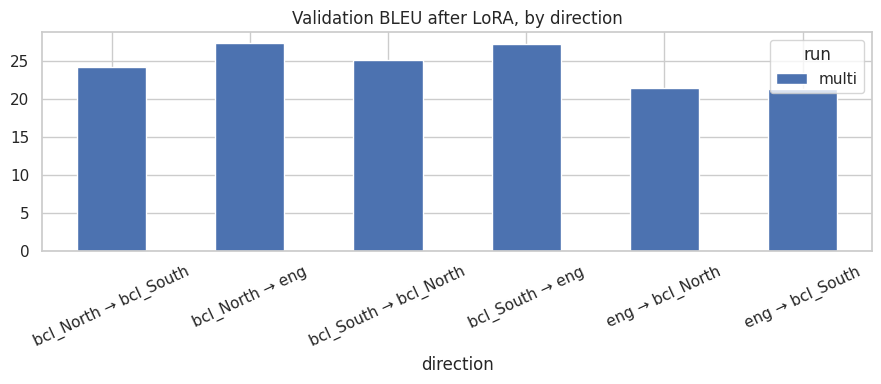

Created phase2_deliverables.zip (70.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
# reference: the v2 results (separate per-dialect adapters, no South<->North, selected by validation loss) from the earlier run
# v3 results (same 6 directions, validation set, beam 4) from the previous run, before the regularisation changes
V3_BLEU = {"bcl_North → eng": 27.24, "eng → bcl_North": 21.30, "bcl_South → eng": 29.05, "eng → bcl_South": 19.04,
           "bcl_South → bcl_North": 25.63, "bcl_North → bcl_South": 24.21}
def _ci_txt(tbl, d):
    return f"{tbl.loc[d, '95% CI low']:.1f}–{tbl.loc[d, '95% CI high']:.1f}" if d in tbl.index else ""
V2_BLEU = {"bcl_North → eng": 25.35, "eng → bcl_North": 20.25, "bcl_South → eng": 30.09, "eng → bcl_South": 16.79}

rows = []
for run in RUN_NAMES:
    p = f"{P2_ROOT}/{run}"
    try:
        cmp_ = pd.read_csv(f"{p}/val_zero_shot_vs_lora.csv"); h_ = pd.read_csv(f"{p}/loss_history.csv")
        meta_ = json.load(open(f"{p}/lora_adapter/bikol_meta.json")); bm_ = pd.read_csv(f"{p}/export_benchmark.csv")
    except FileNotFoundError as e:
        print(f"⚠️ {run}: results missing ({e.filename}) — did the run finish?"); continue
    ad_mb = sum(os.path.getsize(f"{p}/lora_adapter/{f}") for f in os.listdir(f"{p}/lora_adapter") if f.startswith("adapter_model")) / 1e6
    ci_ = pd.read_csv(f"{p}/val_bleu_ci.csv").set_index("direction") if os.path.exists(f"{p}/val_bleu_ci.csv") else pd.DataFrame()
    c_ms = bm_[bm_.variant.str.startswith("C")]["latency_greedy_ms"]
    best_ep = int(h_.loc[h_.val_BLEU.idxmax(), "epoch"]) if "val_BLEU" in h_ else int(h_.loc[h_.val_loss.idxmin(), "epoch"])
    for direction, g_ in cmp_.groupby("direction"):
        zs_ = g_[g_.model.str.startswith("Zero")].iloc[0]; ft_ = g_[~g_.model.str.startswith("Zero")].iloc[0]
        rows.append({"run": run, "direction": direction, "zero-shot BLEU": zs_["BLEU"], "LoRA BLEU": ft_["BLEU"],
                     "BLEU 95% CI": _ci_txt(ci_, direction), "v3 BLEU": V3_BLEU.get(direction, np.nan), "Δ BLEU vs v3": ft_["BLEU"] - V3_BLEU.get(direction, np.nan),
                     "v2 BLEU": V2_BLEU.get(direction, np.nan),
                     "zero-shot chrF++": zs_["chrF++"], "LoRA chrF++": ft_["chrF++"], "LoRA TER": ft_["TER"],
                     "best epoch": best_ep, "adapter MB": round(ad_mb, 1),
                     "greedy ms (merged fp16)": float(c_ms.iloc[0]) if len(c_ms) else np.nan})
both = pd.DataFrame(rows)
if len(both):
    display(both.round(2)); both.to_csv(f"{P2_ROOT}/all_runs_summary.csv", index=False)
    print("Mean LoRA validation BLEU per run:"); display(both.groupby("run")["LoRA BLEU"].mean().round(2).to_frame())
    both.pivot(index="direction", columns="run", values="LoRA BLEU").plot.bar(rot=25, figsize=(9, 4), title="Validation BLEU after LoRA, by direction")
    plt.tight_layout(); plt.savefig(f"{P2_ROOT}/all_runs_bleu.png", dpi=150); plt.show()

# one zip with the adapters + all reports (big merged models / checkpoints are left out)
ZB = "phase2_deliverables.zip"
with zipfile.ZipFile(ZB, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(P2_ROOT):
        if any(s in root for s in ("checkpoints", "merged_fp16", "sweep")): continue
        for f in fs:
            if not f.endswith("int8_state_dict.pt"): z.write(os.path.join(root, f))
print("Created", ZB, f"({os.path.getsize(ZB)/1e6:.1f} MB)")
try:
    from google.colab import files as colab_files; colab_files.download(ZB)
except ImportError:
    pass
